# Forecasting CPU 120 jam: apakah data 30 menit lebih baik dari data 1 jam?

Notebook ini adalah **studi pembanding** untuk `skripsi_forecast_v3.ipynb` (model 1 jam). Pipeline-nya sama (pembersihan, fitur, grid model, aturan seleksi, walk-forward). Bedanya, data masukan sekarang `cleaned_30m_unimputed.csv` dengan resolusi 30 menit.

**Pertanyaan penelitian.** Bila model dilatih dengan data 30 menit, apakah prakiraan **rata-rata CPU per jam 1–120 jam ke depan** lebih akurat dibanding model yang dilatih dengan data 1 jam?

**Kenapa targetnya tetap per jam.** MAE pada deret 30 menit tidak bisa dibandingkan langsung dengan MAE pada deret per jam, karena deret 30 menit lebih berfluktuasi sehingga galatnya pasti lebih besar. Perbandingan yang adil harus memakai **target yang sama**. Karena itu model 30 menit memprediksi 240 langkah (120 jam × 2), lalu prakiraan untuk jam *T* = rata-rata dua langkah di dalam (T − 1 jam, T]. Hasilnya dinilai dengan label resmi per jam dari `cleaned_unimputed.csv`, sama dengan model 1 jam (Hyndman & Athanasopoulos, 2021, §5.8; Hewamalage dkk., 2023).
Akurasi pada resolusi 30 menit tetap dilaporkan terpisah di bagian 10.

## Desain

| Varian | Data latih | Riwayat | Seleksi model | Peran |
|---|---|---|---|---|
| **1 jam** | `cleaned_unimputed.csv` | mulai 16 Okt 2025 | grid lengkap di validation (`skripsi_forecast_v3.ipynb`, sudah beku) | acuan, prediksinya dibaca dari `outputs_v3_baru/` |
| **30 menit** | `cleaned_30m_unimputed.csv` | mulai 16 Okt 2025 (sama) | grid yang sama, dipilih ulang di validation | **perbandingan utama** |
| **30 menit, riwayat panjang** | `cleaned_30m_unimputed.csv` | mulai 1 Agu 2024 | tidak dipilih ulang: memakai konfigurasi beku varian 30 menit | analisis tambahan |

**Yang dijaga sama** dengan model 1 jam: periode validation (Mei–Agu 2026) dan test (Sep–Okt 2026), tanggal refit, origin yang dinilai (tiap 6 jam, tepat di awal jam), batas data 1 Nov 2026 00:00, telemetri terpilih (diambil dari seleksi beku 1 jam), grid model, iterasi boosting, dan aturan seleksi.
Riwayat varian utama dipotong ke awal data 1 jam, supaya selisih yang muncul berasal dari **resolusi**, bukan dari **panjang riwayat**. Pengaruh panjang riwayat diuji terpisah di varian ketiga.

**Penerjemahan fitur ke 30 menit.** Semua jendela waktu dipertahankan dalam satuan jam: lag 24 jam = 48 langkah, rata-rata 168 jam = 336 langkah, profil jam-minggu menjadi profil setengah-jam-minggu (336 slot), dan seterusnya. Selain itu ada beberapa **fitur yang hanya mungkin dengan data 30 menit**: lag 30 menit, perubahan 30 menit terakhir, rata-rata jam terakhir, deviasi 2 jam terakhir, maksimum 6 jam terakhir, dan perubahan 30 menit telemetri.

## Aturan keputusan (ditetapkan sebelum notebook ini dijalankan)

1. Model final varian 30 menit dipilih **hanya** di validation, dengan aturan yang sama dengan model 1 jam (MAE per jam terendah di antara model terbaik per keluarga dan set fitur dan dua ensemble GBDT), lalu dibekukan sebelum test.
2. **Perbandingan utama:** model final 30 menit vs model final 1 jam di periode **test**, pada pasangan (origin, jam target) yang sama. Uji Diebold–Mariano fixed-m (Coroneo & Iacone, 2020).
   - **Lebih baik** bila CI 95% selisih MAE (30 menit − 1 jam) seluruhnya < 0.
   - **Lebih buruk** bila seluruhnya > 0.
   - Selain itu **tidak berbeda nyata**.
3. Hasil validation dan perbandingan per keluarga model dilaporkan sebagai pendukung, bukan penentu.
4. **Catatan kejujuran.** Periode test sudah pernah dilihat saat membangun model 1 jam. Karena itu kesimpulan test di sini **eksploratori**. Bukti konfirmatori hanya dari data setelah 1 November 2026.

**Urutan menjalankan:** jalankan `skripsi_forecast_v3.ipynb` lebih dulu (notebook ini membaca `outputs_v3_baru/seleksi_beku.json` dan `outputs_v3_baru/prediksi.csv.gz`). Semua keluaran notebook ini masuk ke `outputs_30m_baru/`.

## 0. Konfigurasi

In [1]:
import os, json, time, pickle, hashlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
import holidays, sklearn, lightgbm as lgb, xgboost as xgb
from scipy import stats
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings("ignore")

DATA_PATH   = "cleaned_30m_unimputed.csv"     # data 30 menit, timestamp di akhir interval: baris t = rata-rata (t − 30 menit, t]
JAM_PATH    = "cleaned_unimputed.csv"         # data 1 jam: hanya kolom CPU yang dibaca, sebagai label resmi per jam
HOURLY_DIR  = os.environ.get("HOURLY_DIR", "outputs_v3_baru")   # keluaran skripsi_forecast_v3.ipynb (model 1 jam, seleksi beku)
OUT_DIR     = os.environ.get("OUT_DIR", "outputs_30m_baru")   # override lewat env OUT_DIR
DATA_CUTOFF = "2026-11-01 00:00"              # sama dengan model 1 jam; data sesudahnya untuk uji konfirmasi
START_UTAMA = "2025-10-15 23:30"              # awal data 1 jam (16 Okt 2025 00:00) dikurangi 30 menit: riwayat sama dengan model 1 jam
STEP_MIN, SPH = 30, 2                         # menit per langkah, langkah per jam
STEP = pd.Timedelta(minutes=STEP_MIN)
H_JAM, HIGH = 120, 80.0                       # horizon (jam) dan ambang beban tinggi (%)
H = H_JAM * SPH                               # horizon dalam langkah 30 menit (240)
TRAIN_STRIDE, SCORE_STRIDE = 2, 6             # jarak origin training dan origin yang dinilai (jam), sama dengan model 1 jam
SPLIT = {"validation": {"refits": ["2026-05-01", "2026-06-01", "2026-07-01", "2026-08-01"], "end": "2026-09-01"},
         "test":       {"refits": ["2026-09-01", "2026-10-01"], "end": DATA_CUTOFF}}
MAX_GAP, MIN_TARGET = 3 * SPH, 0.95           # celah <= 3 jam (6 langkah) diinterpolasi untuk fitur; origin dinilai bila >= 95% target teramati
N_ITER, LR = 300, 0.05
SEED, N_JOBS = 42, 6
REUSE_CACHE = True
RUN_RIWAYAT_PANJANG = True                    # bagian 11: varian 30 menit dengan riwayat sejak Agu 2024 (sekitar 2x lebih lama dilatih)
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True); os.makedirs(f"{OUT_DIR}/cache", exist_ok=True)

TARGET = "cpu_usage_percent"
METRICS = ["cpu_usage_percent", "sysload_1m", "sysload_5m", "sysload_15m", "memory_usage_percent", "swap_usage_percent",
           "network_rx_bytes_per_sec", "network_tx_bytes_per_sec", "disk_read_bytes_per_sec", "disk_write_bytes_per_sec",
           "disk_read_iops", "disk_write_iops", "process_running_count", "process_blocked_count"]
TELE_ALL = ["sysload_1m", "sysload_15m", "memory_usage_percent", "swap_usage_percent", "network_rx_bytes_per_sec", "network_tx_bytes_per_sec",
            "disk_read_bytes_per_sec", "disk_write_bytes_per_sec", "disk_read_iops", "disk_write_iops", "process_running_count", "process_blocked_count"]
LOG_COLS = {c for c in TELE_ALL if "bytes" in c or "iops" in c or "process" in c}
TELE_LONG = ("sysload_15m", "disk_read_iops")
VERSIONS = {"holidays": holidays.__version__, "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__, "xgboost": xgb.__version__,
            "pandas": pd.__version__, "numpy": np.__version__}
DEVICE  = os.environ.get("ML_DEVICE", "gpu")      # "gpu": XGBoost CUDA + LightGBM GPU; "cpu": semua di CPU. HGB & Ridge (sklearn) selalu CPU
XGB_DEV = {"device": "cuda"} if DEVICE == "gpu" else {}
def _lgb_gpu_ok():                                  # wheel PyPI LightGBM tidak dibangun dengan GPU: bila begitu LightGBM tetap di CPU
    try:
        import numpy as _np, lightgbm as _lgb
        _lgb.train({"device_type": "gpu", "verbose": -1}, _lgb.Dataset(_np.random.rand(200, 2), _np.random.rand(200)), 1); return True
    except Exception: return False
LGB_DEV = {"device_type": "gpu"} if DEVICE == "gpu" and _lgb_gpu_ok() else {}
print(f"Perangkat: XGBoost {'cuda' if XGB_DEV else 'cpu'}, LightGBM {'gpu' if LGB_DEV else 'cpu'}, HGB/Ridge cpu")
xgb.set_config(verbosity=0)                        # sembunyikan peringatan "mismatched devices" saat predict dari array CPU
VERSIONS["device"] = f"xgb:{'cuda' if XGB_DEV else 'cpu'}, lgbm:{'gpu' if LGB_DEV else 'cpu'}"                         # ikut kunci cache: hasil CPU dan GPU tidak tercampur

FAM = {"ridge": "Ridge", "hgb": "HistGradientBoosting", "lgbm": "LightGBM", "xgb": "XGBoost"}
FS = {"cpu": "CPU + kalender", "tele": "CPU + kalender + telemetri terpilih"}
BASE = {"snaive": "Naif musiman mingguan", "mean4w": "Rata-rata 4 minggu"}
RES = {"60": "1 jam", "30": "30 menit", "30P": "30 menit, riwayat panjang"}
RCOL = {"60": "#2a78d6", "30": "#eb6834", "30P": "#1baf7a", "base": "#52514e"}
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e0", "#f1f0eb"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": .6, "font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left"})
FASE = {"validation": "Validation", "test": "Test"}
def show(df, fmt=None, caption=None):
    st = df.style.hide(axis="index").format(fmt or None, na_rep="–", precision=2, escape="html")
    if caption: st = st.set_caption(caption).set_table_styles([{"selector": "caption", "props": "caption-side: top; font-weight: 600; text-align: left;"}])
    display(st)
def sha_file(p): return hashlib.sha256(open(p, "rb").read()).hexdigest()
def sha_obj(o): return hashlib.sha256(json.dumps(o, sort_keys=True, default=str).encode()).hexdigest()

# Seleksi beku model 1 jam: sumber telemetri terpilih dan prediksi acuan
SEL60_PATH, PRED60_PATH = f"{HOURLY_DIR}/seleksi_beku.json", f"{HOURLY_DIR}/prediksi.csv.gz"
assert os.path.exists(SEL60_PATH) and os.path.exists(PRED60_PATH), \
    f"Butuh {SEL60_PATH} dan {PRED60_PATH}. Jalankan skripsi_forecast_v3.ipynb dulu, atau set HOURLY_DIR ke folder keluarannya"
assert sha_file(SEL60_PATH) == open(SEL60_PATH + ".sha256").read().strip(), "seleksi beku model 1 jam berubah setelah dibekukan"
SEL60 = json.load(open(SEL60_PATH)); FINAL60 = SEL60["model_final"]
beda = {k: (v, SEL60["versi_pustaka"].get(k)) for k, v in VERSIONS.items() if SEL60["versi_pustaka"].get(k) != v}
show(pd.DataFrame({"Pustaka": list(VERSIONS), "Versi notebook ini": list(VERSIONS.values()),
                   "Versi model 1 jam": [SEL60["versi_pustaka"].get(k, "–") for k in VERSIONS]}), caption="Versi pustaka")
if beda: display(Markdown(f"**Peringatan:** versi pustaka berbeda dengan saat model 1 jam dibuat: {beda}. Perbandingan tetap sah, tetapi hasil model bisa sedikit berbeda karena versi."))
display(Markdown(f"Acuan 1 jam: `{HOURLY_DIR}`, model final **{FINAL60}** (seleksi dibekukan {SEL60['dibekukan']})."))

Pustaka,Versi notebook ini,Versi model 1 jam
holidays,0.105,0.105
scikit-learn,1.7.2,1.7.2
lightgbm,4.6.0,4.6.0
xgboost,3.1.1,3.1.1
pandas,2.3.3,2.3.3
numpy,2.3.4,2.3.4


Acuan 1 jam: `/Users/johanesvalerio/Downloads/Skripsi/outputs_v3`, model final **Ensemble GBDT · CPU + kalender + telemetri terpilih** (seleksi dibekukan 2026-11-08 14:53:37).

## 1. Data 30 menit dan label per jam

Data 30 menit memakai timestamp di akhir interval: baris *t* = rata-rata (t − 30 menit, t]. Duplikat yang berkonflik ditolak, grid 30 menit dilengkapi, dan rentang nilai dicek.
Baris sesudah **1 Nov 2026 00:00** tidak dibaca.

Dari `cleaned_unimputed.csv` hanya kolom CPU yang dibaca, sebagai **label resmi per jam**. Label inilah yang dipakai untuk menilai model 1 jam, sehingga kedua varian dinilai dengan label yang sama.

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
assert not (set(["timestamp", *METRICS]) - set(raw.columns)), "kolom hilang"
assert raw.timestamp.dt.tz is None, "timestamp harus tanpa zona waktu (WIB lokal)"
assert raw.timestamp.dt.minute.isin([0, 30]).all() and raw.timestamp.dt.second.eq(0).all(), "timestamp harus kelipatan 30 menit"
for c in METRICS: raw[c] = pd.to_numeric(raw[c], errors="raise").astype(float)
dup = raw[raw.timestamp.duplicated(keep=False)]
assert not any(g[c].dropna().nunique() > 1 for _, g in dup.groupby("timestamp") for c in METRICS), "duplikat berkonflik"
full = raw.sort_values("timestamp").groupby("timestamp")[METRICS].first()
full = full.reindex(pd.date_range(full.index.min(), full.index.max(), freq=f"{STEP_MIN}min", name="timestamp"))
for c in ("cpu_usage_percent", "memory_usage_percent", "swap_usage_percent"):
    assert full[c].dropna().between(0, 100).all(), f"{c} di luar 0-100"
assert (full[[c for c in METRICS if "percent" not in c]].fillna(0) >= 0).all().all(), "metrik negatif"

cut = pd.Timestamp(DATA_CUTOFF)
DF_ALL = full.loc[:cut].copy()                                  # seluruh riwayat 30 menit (varian riwayat panjang)
df = DF_ALL.loc[pd.Timestamp(START_UTAMA):].copy()              # varian utama: riwayat sama dengan model 1 jam
DATA_SHA = sha_file(DATA_PATH); del full, raw

jam = pd.read_csv(JAM_PATH, parse_dates=["timestamp"], usecols=["timestamp", TARGET]).groupby("timestamp")[TARGET].first().astype(float)
jam = jam.reindex(pd.date_range(jam.index.min(), jam.index.max(), freq="h", name="timestamp"))
Y_JAM = jam.loc[:cut]; JAM_SHA = sha_file(JAM_PATH); del jam
assert JAM_SHA == SEL60["data_sha256"], "cleaned_unimputed.csv berbeda dengan file yang dipakai model 1 jam"
assert Y_JAM.index.min() - STEP == pd.Timestamp(START_UTAMA), "START_UTAMA harus 30 menit sebelum awal data 1 jam"

per = {"Training awal": (df.index.min(), pd.Timestamp("2026-05-01")), "Validation": (pd.Timestamp("2026-05-01"), pd.Timestamp("2026-09-01")),
       "Test": (pd.Timestamp("2026-09-01"), cut + STEP)}
rows = []
for p_, (a_, b_) in per.items():
    c = df.loc[(df.index >= a_) & (df.index < b_), TARGET]
    rows.append({"Periode": p_, "Dari": f"{c.index.min():%d %b %Y %H:%M}", "Sampai": f"{c.index.max():%d %b %Y %H:%M}", "Langkah 30 menit": len(c),
                 "CPU kosong (langkah)": int(c.isna().sum()), "Rata-rata CPU (%)": c.mean(), "SD": c.std(), "CPU ≥ 80% (% langkah)": 100 * (c >= HIGH).mean()})
c = DF_ALL.loc[:df.index.min() - STEP, TARGET]
rows.append({"Periode": "Riwayat tambahan (hanya bagian 11)", "Dari": f"{c.index.min():%d %b %Y %H:%M}", "Sampai": f"{c.index.max():%d %b %Y %H:%M}",
             "Langkah 30 menit": len(c), "CPU kosong (langkah)": int(c.isna().sum()), "Rata-rata CPU (%)": c.mean(), "SD": c.std(), "CPU ≥ 80% (% langkah)": 100 * (c >= HIGH).mean()})
show(pd.DataFrame(rows), {"Langkah 30 menit": "{:,.0f}", "CPU kosong (langkah)": "{:,.0f}", "Rata-rata CPU (%)": "{:.1f}", "SD": "{:.1f}", "CPU ≥ 80% (% langkah)": "{:.1f}"},
     "Tabel 1. Ringkasan data 30 menit per periode")
display(Markdown(f"Sumber: `{DATA_PATH}` (sha256 `{DATA_SHA[:16]}…`) dan label per jam `{JAM_PATH}` (sha256 `{JAM_SHA[:16]}…`, sama dengan model 1 jam)."))

Periode,Dari,Sampai,Langkah 30 menit,CPU kosong (langkah),Rata-rata CPU (%),SD,CPU ≥ 80% (% langkah)
Training awal,15 Oct 2025 23:30,30 Apr 2026 23:30,"9,457",4,35.6,21.2,4.2
Validation,01 May 2026 00:00,31 Aug 2026 23:30,"5,904",10,40.2,22.3,6.9
Test,01 Sep 2026 00:00,01 Nov 2026 00:00,"2,929",2,41.3,18.1,2.5
Riwayat tambahan (hanya bagian 11),01 Aug 2024 07:30,15 Oct 2025 23:00,"21,152","3,378",35.1,21.0,3.0


Sumber: `cleaned_30m_unimputed.csv` (sha256 `62feaed34acfaf52…`) dan label per jam `cleaned_unimputed.csv` (sha256 `ca0d535357389a51…`, sama dengan model 1 jam).

In [3]:
# Tabel 2: apakah rata-rata dua baris 30 menit sama dengan data 1 jam?
agg = DF_ALL[TARGET].rolling(SPH, min_periods=SPH).mean().reindex(Y_JAM.index)        # rata-rata (t − 1 jam, t]
d_ = (agg - Y_JAM).dropna()
show(pd.DataFrame([{"Jam dibandingkan": len(d_), "MAE (pp)": d_.abs().mean(), "Bias (pp)": d_.mean(), "Selisih maks (pp)": d_.abs().max(),
                    "|selisih| ≤ 0,5 pp (%)": 100 * (d_.abs() <= .5).mean(), "Korelasi": agg.corr(Y_JAM)}]),
     {"Jam dibandingkan": "{:,.0f}", "MAE (pp)": "{:.3f}", "Bias (pp)": "{:+.3f}", "Selisih maks (pp)": "{:.2f}", "|selisih| ≤ 0,5 pp (%)": "{:.1f}", "Korelasi": "{:.4f}"},
     "Tabel 2. Rata-rata dua baris 30 menit vs CPU di data 1 jam (jam yang sama)")
display(Markdown(
    "Kedua file hampir sama tetapi tidak identik, kemungkinan karena keduanya diagregasi terpisah dari data mentah yang lebih rapat. "
    "Karena itu **label resmi** untuk kedua varian adalah CPU dari data 1 jam. Sebagai uji sensitivitas, bagian 9 juga menilai ulang dengan label "
    "*rata-rata dua baris 30 menit*."))
m_ = DF_ALL[TARGET].isna().groupby(DF_ALL.index.to_period("M")).mean().mul(100)
m_ = m_[m_ > 1]
if len(m_): show(pd.DataFrame({"Bulan": m_.index.astype(str), "CPU kosong (%)": m_.values}), {"CPU kosong (%)": "{:.1f}"},
                 "Tabel 3. Bulan dengan CPU 30 menit kosong > 1% (seluruh riwayat)")

Jam dibandingkan,MAE (pp),Bias (pp),Selisih maks (pp),"|selisih| ≤ 0,5 pp (%)",Korelasi
"9,135",0.295,-0.009,6.17,84.2,0.9994


Kedua file hampir sama tetapi tidak identik, kemungkinan karena keduanya diagregasi terpisah dari data mentah yang lebih rapat. Karena itu **label resmi** untuk kedua varian adalah CPU dari data 1 jam. Sebagai uji sensitivitas, bagian 9 juga menilai ulang dengan label *rata-rata dua baris 30 menit*.

Bulan,CPU kosong (%)
2024-08,3.2
2024-09,3.3
2024-10,67.7
2024-11,66.7
2024-12,25.8
2025-01,3.2
2025-02,3.6
2025-04,4.0
2025-07,41.9
2025-09,10.0


## 2. Kalender libur Indonesia

Sama dengan model 1 jam: library `holidays`, kategori libur nasional dan cuti bersama, memakai tanggal **awal** interval. Fiturnya adalah libur nasional, cuti bersama, dan jarak (hari) ke atau dari hari libur terdekat, dibatasi 14 hari.

In [4]:
YEARS = list(range(DF_ALL.index.year.min() - 1, DF_ALL.index.year.max() + 2))
HOL_PUB = holidays.country_holidays("ID", years=YEARS)
HOL_GOV = holidays.country_holidays("ID", years=YEARS, categories=("government",))
cal = pd.DataFrame(0, index=pd.date_range(f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31"), columns=["libur_nasional", "cuti_bersama"])
cal["libur_nasional"] = [int(d in HOL_PUB) for d in cal.index.date]
cal["cuti_bersama"] = [int(d in HOL_GOV) for d in cal.index.date]
off = (cal.libur_nasional + cal.cuti_bersama).gt(0).to_numpy(); i = np.arange(len(cal)); op = i[off]
nx = np.searchsorted(op, i, side="left"); pv = np.searchsorted(op, i, side="right") - 1
cal["hari_ke_libur"] = np.clip(np.where(nx < len(op), op[np.minimum(nx, len(op) - 1)] - i, 99), 0, 14)
cal["hari_sejak_libur"] = np.clip(np.where(pv >= 0, i - op[np.maximum(pv, 0)], 99), 0, 14)
n_ = int(((cal.libur_nasional + cal.cuti_bersama) > 0).loc[DF_ALL.index.min().normalize():cut].sum())
display(Markdown(f"Kalender {YEARS[0]}–{YEARS[-1]} (holidays {holidays.__version__}): {n_} hari libur nasional atau cuti bersama dalam rentang data 30 menit."))

Kalender 2023–2027 (holidays 0.105): 56 hari libur nasional atau cuti bersama dalam rentang data 30 menit.

## 3. Pembersihan data kosong

Aturannya sama dengan model 1 jam, dengan satuan waktu yang sama:

| Aturan | Isi |
|---|---|
| C1 | Celah ≤ 3 jam (≤ 6 langkah 30 menit) diinterpolasi linear, **hanya untuk input fitur**. Celah lebih panjang dianggap *outage*. |
| C2 | Origin dinilai bila CPU teramati di origin, riwayat 168 jam lengkap setelah C1, dan ≥ 95% dari 240 target 30 menit teramati. |
| C3 | Model telemetri dipakai di origin *t* hanya bila semua telemetri terpilih teramati dan tidak ada outage di jendela fiturnya. Selain itu dipakai model **CPU + kalender** dari keluarga yang sama. |

In [5]:
def gap_runs(d):
    rows = []
    for c in d.columns:
        na = d[c].isna()
        if not na.any(): continue
        g = (na != na.shift()).cumsum()
        for _, s in d.index[na].to_series().groupby(g[na]): rows.append({"kolom": c, "mulai": s.iloc[0], "selesai": s.iloc[-1], "langkah": len(s)})
    return pd.DataFrame(rows, columns=["kolom", "mulai", "selesai", "langkah"])

def impute_short(d, max_gap=MAX_GAP):
    out = d.copy()
    for c in d.columns:
        na = d[c].isna()
        if not na.any(): continue
        run = na.groupby((na != na.shift()).cumsum()).transform("sum")
        fill = d[c].interpolate(method="time", limit_area="inside")
        short = na & (run <= max_gap) & fill.notna()
        out.loc[short, c] = fill[short]
    return out

gaps = gap_runs(df[METRICS])
ev = gaps.groupby(["mulai", "selesai", "langkah"]).kolom.apply(list).reset_index()
show(pd.DataFrame({"Mulai": ev.mulai.dt.strftime("%d %b %Y %H:%M"), "Selesai": ev.selesai.dt.strftime("%d %b %Y %H:%M"), "Langkah": ev.langkah,
                   "Durasi (jam)": ev.langkah / SPH, "Metrik kosong": ev.kolom.apply(len), "CPU ikut kosong": ev.kolom.apply(lambda k: "ya" if TARGET in k else "tidak"),
                   "Tindakan": np.where(ev.langkah <= MAX_GAP, "C1: diinterpolasi untuk fitur", "outage: tidak diimputasi")}),
     {"Langkah": "{:d}", "Durasi (jam)": "{:.1f}", "Metrik kosong": "{:d}"}, f"Tabel 4. Celah data 30 menit, varian utama ({df.index.min():%d %b %Y} s.d. {DATA_CUTOFF})")

Mulai,Selesai,Langkah,Durasi (jam),Metrik kosong,CPU ikut kosong,Tindakan
02 Feb 2026 20:00,02 Feb 2026 20:00,1,0.5,8,ya,C1: diinterpolasi untuk fitur
03 Feb 2026 10:00,03 Feb 2026 10:00,1,0.5,6,tidak,C1: diinterpolasi untuk fitur
03 Feb 2026 10:00,03 Feb 2026 11:00,3,1.5,1,ya,C1: diinterpolasi untuk fitur
03 Feb 2026 10:30,03 Feb 2026 11:00,2,1.0,7,tidak,C1: diinterpolasi untuk fitur
03 Feb 2026 11:00,03 Feb 2026 11:00,1,0.5,6,tidak,C1: diinterpolasi untuk fitur
14 Jun 2026 00:00,14 Jun 2026 02:00,5,2.5,7,ya,C1: diinterpolasi untuk fitur
14 Jun 2026 00:30,14 Jun 2026 02:00,4,2.0,7,tidak,C1: diinterpolasi untuk fitur
14 Jun 2026 07:30,14 Jun 2026 07:30,1,0.5,8,ya,C1: diinterpolasi untuk fitur
15 Aug 2026 23:30,16 Aug 2026 01:00,4,2.0,8,ya,C1: diinterpolasi untuk fitur
16 Aug 2026 00:00,16 Aug 2026 01:00,3,1.5,6,tidak,C1: diinterpolasi untuk fitur


## 4. Telemetri

Telemetri **tidak dipilih ulang**. Notebook ini memakai daftar telemetri terpilih dari seleksi beku model 1 jam (`seleksi_beku.json`), supaya kedua varian memakai input yang sama.
Aturan pemilihan di notebook 1 jam juga tidak bisa diulang di sini, karena data 30 menit berhenti tepat di 1 Nov 2026 sehingga syarat "masih tersedia di data baru" tidak bisa diperiksa.

In [6]:
TELE = list(SEL60["telemetri_terpilih"])
assert set(TELE) <= set(TELE_ALL)
show(pd.DataFrame({"Telemetri terpilih (dari model 1 jam)": TELE, "Kosong, varian utama (%)": [100 * df[m].isna().mean() for m in TELE],
                   "Kosong, seluruh riwayat (%)": [100 * DF_ALL[m].isna().mean() for m in TELE]}),
     {"Kosong, varian utama (%)": "{:.2f}", "Kosong, seluruh riwayat (%)": "{:.2f}"}, "Tabel 5. Telemetri yang dipakai")

Telemetri terpilih (dari model 1 jam),"Kosong, varian utama (%)","Kosong, seluruh riwayat (%)"
sysload_1m,0.07,8.55
sysload_15m,0.07,8.55
network_rx_bytes_per_sec,0.07,8.55
network_tx_bytes_per_sec,0.07,8.55
disk_read_bytes_per_sec,0.07,8.55
disk_write_bytes_per_sec,0.07,8.55
disk_read_iops,0.07,8.55
disk_write_iops,0.07,8.61


## 5. Fitur, origin, dan uji kebocoran

Definisi fitur sama dengan model 1 jam. Semua jendela tetap dalam satuan jam dan dikonversi ke langkah 30 menit:
- **CPU:** nilai saat ini, lag 1–168 jam, rolling 24/72/168 jam, tren 168 vs 672 jam, perubahan minggu ke minggu, dan jumlah jam ≥ 80%.
- **Pola musiman:** CPU pada **setengah jam yang sama** 1–4 minggu sebelumnya, rata-ratanya, profil setengah-jam-minggu (336 slot), dan anomali saat origin.
- **Kalender pada waktu target:** jam, menit (0 atau 30), hari, akhir pekan, libur, dan jarak ke libur.
- **Horizon** *h* dalam jam (0,5–120).
- **Telemetri terpilih:** nilai saat ini, rata-rata 24 jam, dan lag 24 jam. Untuk sysload_15m dan disk_read_iops ditambah rata-rata dan deviasi 168 jam.

**Fitur yang hanya ada di varian 30 menit:** `cpu_lag_30m`, `cpu_diff_30m`, `cpu_jam_terakhir` (rata-rata 1 jam terakhir, sama dengan "CPU saat ini" di model 1 jam), `cpu_std_2jam`, `cpu_max_6jam`, dan `tele_*_diff_30m`.

**Label.** Model dilatih dengan target 30 menit. Prakiraan per jam = rata-rata prakiraan dua langkah di dalam jam target.

In [7]:
CPU_LAGS = (1, 2, 3, 6, 12, 24, 48, 72, 168); ROLLS = (24, 72, 168)            # dalam jam; dikali SPH menjadi langkah
NSLOT = 168 * SPH
def slot(ix): s = ix - STEP; return (s.dayofweek * 24 * SPH + s.hour * SPH + s.minute // STEP_MIN).to_numpy()
FEATS_30_ONLY = ["cpu_lag_30m", "cpu_diff_30m", "cpu_jam_terakhir", "cpu_std_2jam", "cpu_max_6jam"]

def origin_features(d):
    c = d[TARGET]; J = SPH; out = {"cpu_now": c}
    for l in CPU_LAGS: out[f"cpu_lag_{l}"] = c.shift(l * J)
    for w in ROLLS:
        r = c.rolling(w * J, min_periods=w * J)
        out[f"cpu_mean_{w}"], out[f"cpu_std_{w}"], out[f"cpu_max_{w}"], out[f"cpu_min_{w}"] = r.mean(), r.std(ddof=0), r.max(), r.min()
    out["cpu_diff_1"] = c - c.shift(J)
    hi = c.ge(HIGH).astype(float).where(c.notna())
    out["cpu_jam_ge80_24"] = hi.rolling(24 * J, min_periods=24 * J).sum() / J; out["cpu_jam_ge80_168"] = hi.rolling(168 * J, min_periods=160 * J).sum() / J
    m672 = c.rolling(672 * J, min_periods=600 * J).mean()
    out["cpu_mean_672"] = m672; out["cpu_tren_168_672"] = out["cpu_mean_168"] - m672
    out["cpu_wow_24"] = out["cpu_mean_24"] - out["cpu_mean_24"].shift(168 * J); out["cpu_wow_168"] = out["cpu_mean_168"] - out["cpu_mean_168"].shift(168 * J)
    out["cpu_diff_168"] = c - c.shift(168 * J)
    # Hanya mungkin dengan data 30 menit
    out["cpu_lag_30m"] = c.shift(1); out["cpu_diff_30m"] = c - c.shift(1)
    out["cpu_jam_terakhir"] = c.rolling(J, min_periods=J).mean()
    out["cpu_std_2jam"] = c.rolling(2 * J, min_periods=2 * J).std(ddof=0); out["cpu_max_6jam"] = c.rolling(6 * J, min_periods=6 * J).max()
    for m in TELE:
        v = np.log1p(d[m].clip(lower=0)) if m in LOG_COLS else d[m]
        out[f"tele_{m}_now"] = v; out[f"tele_{m}_mean_24"] = v.rolling(24 * J, min_periods=18 * J).mean(); out[f"tele_{m}_lag_24"] = v.shift(24 * J)
        out[f"tele_{m}_diff_30m"] = v - v.shift(1)
        if m in TELE_LONG:
            r = v.rolling(168 * J, min_periods=150 * J).mean(); out[f"tele_{m}_mean_168"] = r; out[f"tele_{m}_dev_168"] = v - r
    s = d.index - STEP
    out["origin_jam"] = pd.Series(s.hour, index=d.index).astype(float); out["origin_hari"] = pd.Series(s.dayofweek, index=d.index).astype(float)
    return pd.DataFrame(out, index=d.index)

def how_profile(c):
    """prof[i,k] = rata-rata CPU pada baris <= i dengan slot setengah-jam-minggu k (ekspansif, kausal)."""
    hw = slot(c.index); v = c.to_numpy(float); ok = np.isfinite(v)
    oh = np.zeros((len(v), NSLOT), np.float32); oh[np.arange(len(v))[ok], hw[ok]] = 1.0
    sums = np.cumsum(oh * np.where(ok, v, 0)[:, None], axis=0, dtype=np.float64); cnt = np.cumsum(oh, axis=0, dtype=np.float64)
    with np.errstate(invalid="ignore", divide="ignore"): return np.where(cnt > 0, sums / cnt, np.nan)

META = ("origin", "target_time", "y", "target_jam", "h_jam")
def build_rows(d, of, prof, origins, y_raw):
    pos = d.index.get_indexer(origins); assert (pos >= 0).all()
    n = len(origins); P = np.repeat(pos, H); K = np.tile(np.arange(1, H + 1), n); tp = P + K; Hh = K / SPH
    cp = d[TARGET].to_numpy(float); N = len(cp); W1 = 168 * SPH
    X = pd.DataFrame(of.to_numpy(np.float32)[P], columns=of.columns); X["h"] = Hh.astype(np.float32)
    tt = d.index[0] + pd.to_timedelta(tp * STEP_MIN, unit="min"); s = tt - STEP; dd = s.normalize()
    assert dd.isin(cal.index).all(), "kalender tidak mencakup tanggal target"
    hf = s.hour + s.minute / 60
    X["t_jam"] = s.hour; X["t_menit"] = s.minute; X["t_hari"] = s.dayofweek
    X["t_jam_sin"] = np.sin(2 * np.pi * hf / 24); X["t_jam_cos"] = np.cos(2 * np.pi * hf / 24); X["t_akhir_pekan"] = (s.dayofweek >= 5).astype(float)
    for c_ in ("libur_nasional", "cuti_bersama", "hari_ke_libur", "hari_sejak_libur"): X[f"t_{c_}"] = cal[c_].reindex(dd).to_numpy(float)
    X["t_tanggal"] = s.day; X["t_hari_ke_akhir_bulan"] = s.days_in_month - s.day
    tslot = (s.dayofweek * 24 * SPH + s.hour * SPH + s.minute // STEP_MIN).to_numpy(); X["profil_jam_minggu"] = prof[P, tslot]
    for k in (1, 2, 3, 4):
        src = tp - W1 * k; assert not (src > P).any(), "sumber musiman setelah origin"
        X[f"naif_{k}minggu"] = np.where(src >= 0, cp[np.clip(src, 0, N - 1)], np.nan)
    sn = X[[f"naif_{k}minggu" for k in (1, 2, 3, 4)]]
    X["rata_4minggu"] = sn.mean(axis=1, skipna=True).fillna(X["profil_jam_minggu"]).fillna(X["cpu_now"])
    for tau in (3, 12, 48): X[f"cpu_now_decay_{tau}"] = X["cpu_now"] * np.exp(-Hh / tau)
    hw_all = slot(d.index); a_now = cp[pos] - prof[pos, hw_all[pos]]
    acc = np.zeros(n); cnt = np.zeros(n)
    for k in range(24 * SPH):
        q = np.clip(pos - k, 0, N - 1); v = cp[q] - prof[pos, hw_all[q]]; ok = (pos - k >= 0) & np.isfinite(v); acc += np.where(ok, v, 0.0); cnt += ok
    a_24 = np.where(cnt == 24 * SPH, acc / (24 * SPH), np.nan)
    s4 = np.zeros(n); ok4 = np.ones(n, bool)
    for k in (1, 2, 3, 4):
        q = pos - W1 * k; v = np.where(q >= 0, cp[np.clip(q, 0, N - 1)], np.nan); ok4 &= np.isfinite(v); s4 += np.where(np.isfinite(v), v, 0)
    a_4w = np.where(ok4, cp[pos] - s4 / 4, np.nan)
    A_now, A_24, A_4w = (np.repeat(x, H) for x in (a_now, a_24, a_4w))
    X["anom_now"] = A_now; X["anom_24"] = A_24; X["anom_4minggu"] = A_4w
    for tau in (1, 3, 12, 48): X[f"anom_decay_{tau}"] = A_now * np.exp(-Hh / tau)
    for tau in (3, 24): X[f"anom4w_decay_{tau}"] = A_4w * np.exp(-Hh / tau)
    for tau in (3, 12): X[f"dasar_plus_anom_{tau}"] = X["rata_4minggu"] + np.nan_to_num(A_now) * np.exp(-Hh / tau)
    feat = list(X.columns); X[feat] = X[feat].astype(np.float32)
    X["origin"] = d.index[P]; X["target_time"] = tt; X["y"] = y_raw.reindex(tt).to_numpy()      # label 30 menit dari CPU mentah
    X["target_jam"] = tt.ceil("h"); X["h_jam"] = np.ceil(Hh).astype(np.int16)                    # jam target per jam: (T − 1 jam, T]
    return X

def siapkan(d, label):
    """Semua bahan model untuk satu varian data: fitur, origin yang dinilai (C2), fallback telemetri (C3), dan baris training."""
    feat_df = impute_short(d[METRICS]); cpu_raw = d[TARGET]
    hist_ok = feat_df[TARGET].notna().astype(int).rolling(168 * SPH + 1).sum().eq(168 * SPH + 1)
    fut_frac = cpu_raw.notna().astype(float)[::-1].rolling(H, min_periods=H).sum()[::-1].shift(-1) / H
    on_grid = (d.index.minute == 0) & (d.index.hour % SCORE_STRIDE == 0)
    elig = d.index[(cpu_raw.notna() & hist_ok & fut_frac.ge(MIN_TARGET)).fillna(False).to_numpy() & on_grid]
    outage = pd.DataFrame({m: feat_df[m].isna().astype(int).rolling((168 if m in TELE_LONG else 48) * SPH, min_periods=1).max().astype(bool) | d[m].isna() for m in TELE})
    of = origin_features(feat_df); prof = how_profile(feat_df[TARGET])
    cand = pd.date_range((d.index[0] + pd.Timedelta(hours=168)).ceil(f"{TRAIN_STRIDE}h"), d.index[-1], freq=f"{TRAIN_STRIDE}h")
    cand = cand[d.loc[cand, [TARGET] + TELE].notna().all(axis=1).to_numpy()]
    tr = build_rows(feat_df, of, prof, cand, cpu_raw); tr = tr[tr.y.notna()].reset_index(drop=True)
    return {"label": label, "feat_df": feat_df, "cpu_raw": cpu_raw, "elig": elig, "fallback": outage.any(axis=1), "of": of, "prof": prof, "TR": tr}

def phase_origins(ctx, ph, a=None, b=None):
    """Origin fase: a <= t < b dan seluruh 120 jam target masih di dalam fase."""
    sp = SPLIT[ph]; end = pd.Timestamp(sp["end"]); a = a or pd.Timestamp(sp["refits"][0]); b = b or end
    return [t for t in ctx["elig"] if a <= t < b and t + pd.Timedelta(hours=H_JAM) <= end]

t0 = time.time(); CTX = siapkan(df, "utama")
FEATS_ALL = [c for c in CTX["TR"].columns if c not in META]
FEATS = {"cpu": [c for c in FEATS_ALL if not c.startswith("tele_")], "tele": FEATS_ALL}
rows = [{"Set fitur": FS[k], "Jumlah fitur": len(v), "Fitur telemetri": sum(c.startswith("tele_") for c in v),
         "Fitur khusus 30 menit": sum(c in FEATS_30_ONLY or c.endswith("_diff_30m") for c in v)} for k, v in FEATS.items()]
show(pd.DataFrame(rows), {"Jumlah fitur": "{:d}", "Fitur telemetri": "{:d}", "Fitur khusus 30 menit": "{:d}"}, "Tabel 6. Set fitur varian 30 menit")
rows = [{"Fase": FASE[ph], "Origin dinilai": len(phase_origins(CTX, ph)), "Origin dengan fallback": int(CTX["fallback"].reindex(phase_origins(CTX, ph)).sum()),
         "Refit": ", ".join(pd.Timestamp(r).strftime("%d %b") for r in SPLIT[ph]["refits"])} for ph in SPLIT]
show(pd.DataFrame(rows), {"Origin dinilai": "{:d}", "Origin dengan fallback": "{:d}"},
     f"Tabel 7. Origin per fase (baris training 30 menit: {len(CTX['TR']):,}; disiapkan dalam {time.time() - t0:.0f} detik)")

Set fitur,Jumlah fitur,Fitur telemetri,Fitur khusus 30 menit
CPU + kalender,70,0,5
CPU + kalender + telemetri terpilih,106,36,13


Fase,Origin dinilai,Origin dengan fallback,Refit
Validation,471,0,"01 May, 01 Jun, 01 Jul, 01 Aug"
Test,225,0,"01 Sep, 01 Oct"


In [8]:
# Uji kebocoran: fitur di origin t tidak boleh berubah bila semua data sesudah t diacak (termasuk efek interpolasi)
def leak_ok(t):
    pert = df.copy(); fut = pert.index > t
    pert.loc[fut, METRICS] = np.random.default_rng(0).uniform(1, 100, size=(int(fut.sum()), len(METRICS)))
    fa, fb = impute_short(df[METRICS]), impute_short(pert[METRICS])
    ra = build_rows(fa, origin_features(fa), how_profile(fa[TARGET]), pd.DatetimeIndex([t]), CTX["cpu_raw"])
    rb = build_rows(fb, origin_features(fb), how_profile(fb[TARGET]), pd.DatetimeIndex([t]), pert[TARGET])
    cols = [c for c in FEATS_ALL if not (c.startswith("tele_") and CTX["fallback"][t])]
    return bool(np.allclose(ra[cols].to_numpy(float), rb[cols].to_numpy(float), equal_nan=True)), not np.allclose(ra.y, rb.y, equal_nan=True)
pts = [g.selesai + pd.Timedelta(hours=k) for _, g in gaps[gaps.kolom == TARGET].iterrows() for k in (1, 2, 5)] + [pd.Timestamp("2026-07-15 12:00"), pd.Timestamp("2026-10-20 12:00")]
pts = sorted({t.ceil("h") for t in pts if t.ceil("h") in df.index and t.ceil("h") + pd.Timedelta(hours=H_JAM) <= df.index[-1]})
rows = []
for t in pts:
    ok, ych = leak_ok(t); rows.append({"Origin": f"{t:%d %b %Y %H:%M}", "Fitur tidak berubah": "lolos" if ok else "GAGAL", "Label ikut berubah (kontrol)": "ya" if ych else "TIDAK"})
r0 = build_rows(CTX["feat_df"], CTX["of"], CTX["prof"], pd.DatetimeIndex([pd.Timestamp("2026-07-15 12:00")]), CTX["cpu_raw"])
r1 = build_rows(CTX["feat_df"], CTX["of"], CTX["prof"], pd.DatetimeIndex([pd.Timestamp("2025-12-25 23:00")]), CTX["cpu_raw"])
checks = [("target_time − origin = h (jam)", ((r0.target_time - r0.origin) / pd.Timedelta(hours=1)).eq(r0.h).all()),
          ("y = CPU 30 menit mentah pada target_time", np.allclose(r0.y, CTX["cpu_raw"].reindex(r0.target_time), equal_nan=True)),
          ("naif 1 minggu = CPU(t + h − 168 jam)", np.allclose(r0.naif_1minggu, CTX["feat_df"][TARGET].reindex(r0.target_time - pd.Timedelta(hours=168)), equal_nan=True)),
          ("dua langkah per jam target, h_jam = 1..120", r0.groupby("target_jam").size().eq(SPH).all() and r0.h_jam.min() == 1 and r0.h_jam.max() == H_JAM),
          ("jam target = origin + h_jam", ((r0.target_jam - r0.origin) / pd.Timedelta(hours=1)).eq(r0.h_jam).all()),
          ("langkah 23:30 dan 00:00 26 Des mengikuti libur Natal 25 Des", r1.t_libur_nasional.iloc[:2].eq(1).all() and r1.t_jam.iloc[:2].eq(23).all())]
lk = pd.DataFrame(rows); show(lk, caption="Tabel 8a. Uji kebocoran: origin setelah tiap celah CPU, pertengahan Juli, dan Oktober")
show(pd.DataFrame([{"Cek": n, "Hasil": "lolos" if ok else "GAGAL"} for n, ok in checks]), caption="Tabel 8b. Cek konstruksi baris")
assert (lk["Fitur tidak berubah"] == "lolos").all() and (lk["Label ikut berubah (kontrol)"] == "ya").all() and all(ok for _, ok in checks)

Origin,Fitur tidak berubah,Label ikut berubah (kontrol)
02 Feb 2026 21:00,lolos,ya
02 Feb 2026 22:00,lolos,ya
03 Feb 2026 01:00,lolos,ya
03 Feb 2026 12:00,lolos,ya
03 Feb 2026 13:00,lolos,ya
03 Feb 2026 16:00,lolos,ya
14 Jun 2026 03:00,lolos,ya
14 Jun 2026 04:00,lolos,ya
14 Jun 2026 07:00,lolos,ya
14 Jun 2026 09:00,lolos,ya


Cek,Hasil
target_time − origin = h (jam),lolos
y = CPU 30 menit mentah pada target_time,lolos
naif 1 minggu = CPU(t + h − 168 jam),lolos
"dua langkah per jam target, h_jam = 1..120",lolos
jam target = origin + h_jam,lolos
langkah 23:30 dan 00:00 26 Des mengikuti libur Natal 25 Des,lolos


## 6. Model dan seleksi di validation

Kandidat, grid, dan aturan seleksi **sama persis** dengan model 1 jam:
- HistGradientBoosting, LightGBM, XGBoost (loss L1, 300 iterasi, learning rate 0,05, tanpa early stopping).
- Target CPU langsung atau residual terhadap rata-rata 4 minggu. Untuk boosting, tanpa bobot atau dengan bobot waktu half-life 180 hari.
- Konfigurasi terbaik per keluarga dan set fitur dipilih dengan MAE validation terendah. Ensemble GBDT = rata-rata tiga boosting terbaik. Model final = MAE validation terendah.

Satu-satunya perbedaan: MAE dihitung pada **prakiraan per jam** (rata-rata dua langkah 30 menit), dinilai dengan label resmi per jam. Ini metrik yang sama dengan seleksi model 1 jam.
Seleksi dibekukan dengan hash sebelum test dijalankan.

In [9]:
def recency_w(tr, start, hl):
    if not hl: return None
    return np.power(0.5, ((start - tr.target_time).dt.total_seconds().to_numpy() / 86400.0) / hl)
def ridge_X(X):
    sl = (X["t_jam"].astype(int) * SPH + X["t_menit"].astype(int) // STEP_MIN)
    oh = pd.get_dummies(sl, prefix="s").reindex(columns=[f"s_{i}" for i in range(24 * SPH)], fill_value=0)
    ow = pd.get_dummies(X["t_hari"].astype(int), prefix="d").reindex(columns=[f"d_{i}" for i in range(7)], fill_value=0)
    return np.hstack([X.to_numpy(np.float32), oh.to_numpy(np.float32), ow.to_numpy(np.float32)])   # float32: baris 30 menit 2x lebih banyak
def make_model(sp):
    k = sp["kind"]
    if k == "ridge": return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), Ridge(alpha=sp["alpha"]))
    if k == "hgb": return HistGradientBoostingRegressor(loss="absolute_error", max_iter=N_ITER, learning_rate=LR, max_leaf_nodes=15, min_samples_leaf=50, early_stopping=False, random_state=SEED)
    if k == "lgbm": return lgb.LGBMRegressor(objective="l1", n_estimators=N_ITER, learning_rate=LR, num_leaves=15, min_child_samples=50, subsample=.8, subsample_freq=1,
                                             colsample_bytree=.8, n_jobs=N_JOBS, random_state=SEED, verbose=-1, **LGB_DEV)
    if k == "xgb": return xgb.XGBRegressor(objective="reg:absoluteerror", n_estimators=N_ITER, learning_rate=LR, max_depth=4, min_child_weight=50, subsample=.8,
                                           colsample_bytree=.8, tree_method="hist", n_jobs=N_JOBS, random_state=SEED, **XGB_DEV)
def fit_predict(sp, tr, te, start):
    f = FEATS[sp["fs"]]; resid = sp["target"] == "resid"
    Xtr = ridge_X(tr[f]) if sp["kind"] == "ridge" else tr[f].to_numpy(np.float32)
    Xte = ridge_X(te[f]) if sp["kind"] == "ridge" else te[f].to_numpy(np.float32)
    ytr = (tr.y - tr.rata_4minggu).to_numpy(float) if resid else tr.y.to_numpy(float)
    w = recency_w(tr, start, sp.get("hl")); m = make_model(sp)
    m.fit(Xtr, ytr, ridge__sample_weight=w) if sp["kind"] == "ridge" else m.fit(Xtr, ytr, sample_weight=w)
    del Xtr
    return np.clip(m.predict(Xte) + (te.rata_4minggu.to_numpy(float) if resid else 0.0), 0, 100)
def folds(ctx, ph):
    sp = SPLIT[ph]; refits = [pd.Timestamp(r) for r in sp["refits"]] + [pd.Timestamp(sp["end"])]
    for a, b in zip(refits[:-1], refits[1:]):
        so = phase_origins(ctx, ph, a, b)
        te = build_rows(ctx["feat_df"], ctx["of"], ctx["prof"], pd.DatetimeIndex(so), ctx["cpu_raw"])    # semua 240 langkah, juga yang labelnya kosong
        tr = ctx["TR"][ctx["TR"].origin + pd.Timedelta(hours=H_JAM) <= a]
        assert tr.target_time.max() <= a, "label training melewati waktu refit (kebocoran)"
        yield a, tr, te
def spec_key(sp): return "|".join(str(sp.get(k)) for k in ("kind", "fs", "target", "hl", "alpha"))
def spec_label(sp):
    s = f"{FAM[sp['kind']]} · {FS[sp['fs']]} · target {'residual' if sp['target'] == 'resid' else 'langsung'}"
    return s + (f" · alpha {sp['alpha']:g}" if sp["kind"] == "ridge" else f" · bobot {'half-life ' + str(sp['hl']) + ' hari' if sp['hl'] else 'rata'}")
def run_phase(ctx, ph, specs):
    key = sha_obj([ctx["label"], ph, [spec_key(s) for s in specs], FEATS, [str(t) for t in ctx["elig"]], len(ctx["TR"]), N_ITER, LR, VERSIONS, DATA_SHA])[:12]
    path = f"{OUT_DIR}/cache/{ctx['label']}_{ph}_{key}.pkl"
    if REUSE_CACHE and os.path.exists(path): return pickle.load(open(path, "rb")), "cache"
    t0 = time.time(); parts, log = [], []
    for start, tr, te in folds(ctx, ph):
        base = te[["origin", "target_time", "target_jam", "h", "h_jam", "y"]].copy(); base["refit"] = start; base["phase"] = ph
        base["snaive"] = te.naif_1minggu.to_numpy(float); base["mean4w"] = te.rata_4minggu.to_numpy(float)
        for sp in specs:
            t1 = time.time(); base[spec_key(sp)] = fit_predict(sp, tr, te, start).astype(np.float32)
            log.append({"varian": ctx["label"], "refit": str(start.date()), "model": spec_label(sp), "baris_training": len(tr), "detik": round(time.time() - t1, 1)})
            print(f"  {ctx['label']} {ph} {start.date()} {spec_label(sp)}: {time.time() - t1:.0f} s", flush=True)
        parts.append(base); del tr, te
    out = (pd.concat(parts, ignore_index=True), pd.DataFrame(log)); pickle.dump(out, open(path, "wb"))
    return out, f"dilatih {(time.time() - t0) / 60:.1f} menit"

def apply_fallback(ctx, p, specs):
    """C3: di origin dengan telemetri tidak lengkap, model telemetri memakai prediksi keluarga yang sama dengan set CPU + kalender."""
    fb = ctx["fallback"].reindex(p.origin).to_numpy()
    for sp in specs:
        if sp["fs"] != "tele": continue
        k, kt = spec_key(sp), spec_key(dict(sp, fs="cpu"))
        if fb.any(): assert kt in p, f"fallback butuh {kt}"; p.loc[fb, k] = p.loc[fb, kt]
    p["fallback"] = fb; return p
def ke_jam(p, cols):
    """Prakiraan per jam = rata-rata dua langkah 30 menit di (T − 1 jam, T]. y = label resmi data 1 jam; y30 = rata-rata dua label 30 menit (sensitivitas)."""
    g = p.groupby(["origin", "target_jam"], sort=True)
    a = g[cols].mean(); n = g.size(); ny = g.y.count(); a["y30"] = g.y.mean().where(ny == SPH)
    a = a[n == SPH].reset_index().rename(columns={"target_jam": "target_time"})
    a["h"] = ((a.target_time - a.origin) / pd.Timedelta(hours=1)).round().astype(int)
    a["y"] = Y_JAM.reindex(a.target_time).to_numpy()
    return a.merge(p.groupby("origin")[["phase", "refit", "fallback"]].first().reset_index(), on="origin", how="left")

KINDS = ("hgb", "lgbm", "xgb")                     # sama dengan model 1 jam; Ridge hanya dinilai di skripsi_forecast_v3 (bagian 8.3)
GRID = [{"kind": kind, "fs": fs, "target": target, "hl": hl, "alpha": None}   # urutan sama dengan versi lama -> kunci cache tidak berubah
        for fs in FS for target in ("raw", "resid") for kind in KINDS for hl in (None, 180)]
(PV, LOGV), how_v = run_phase(CTX, "validation", GRID)
PV = apply_fallback(CTX, PV, GRID)
print(f"validation: {how_v} | {len(GRID)} konfigurasi | {PV.origin.nunique()} origin | {len(PV):,} baris 30 menit")

  utama validation 2026-05-01 Ridge · CPU + kalender · target langsung · alpha 10: 11 s


  utama validation 2026-05-01 Ridge · CPU + kalender · target langsung · alpha 100: 11 s


  utama validation 2026-05-01 Ridge · CPU + kalender · target langsung · alpha 1000: 6 s


  utama validation 2026-05-01 HistGradientBoosting · CPU + kalender · target langsung · bobot rata: 27 s


  utama validation 2026-05-01 HistGradientBoosting · CPU + kalender · target langsung · bobot half-life 180 hari: 47 s


  utama validation 2026-05-01 LightGBM · CPU + kalender · target langsung · bobot rata: 11 s


... (135 outputs left out)

  utama validation 2026-08-01 LightGBM · CPU + kalender + telemetri terpilih · target residual · bobot half-life 180 hari: 28 s


  utama validation 2026-08-01 XGBoost · CPU + kalender + telemetri terpilih · target residual · bobot rata: 28 s


  utama validation 2026-08-01 XGBoost · CPU + kalender + telemetri terpilih · target residual · bobot half-life 180 hari: 28 s


validation: dilatih 206.0 menit | 36 konfigurasi | 471 origin | 113,040 baris 30 menit


In [10]:
PVJ = ke_jam(PV, ["snaive", "mean4w"] + [spec_key(s) for s in GRID]); PVJe = PVJ[PVJ.y.notna()]
mae = lambda p, c: float((p[c] - p.y).abs().mean())
res = pd.DataFrame([{"Keluarga": FAM[s["kind"]], "Set fitur": FS[s["fs"]], "Target": "residual" if s["target"] == "resid" else "langsung",
                     "Bobot / alpha": (f"alpha {s['alpha']:g}" if s["kind"] == "ridge" else ("half-life 180 hari" if s["hl"] else "rata")),
                     "MAE validation (per jam)": mae(PVJe, spec_key(s)), "_key": spec_key(s), "_spec": s} for s in GRID])
BEST = {}
for (kf, fs), g in res.groupby([res._spec.map(lambda s: s["kind"]), res._spec.map(lambda s: s["fs"])]): BEST[(kf, fs)] = g.loc[g["MAE validation (per jam)"].idxmin(), "_spec"]
res["Terpilih"] = ["✓" if any(spec_key(b) == k for b in BEST.values()) else "" for k in res._key]
show(res.drop(columns=["_key", "_spec"]).sort_values(["Keluarga", "Set fitur", "MAE validation (per jam)"]), {"MAE validation (per jam)": "{:.3f}"},
     "Tabel 9. Grid seleksi varian 30 menit di validation (✓ = terbaik per keluarga dan set fitur)")

Keluarga,Set fitur,Target,Bobot / alpha,MAE validation (per jam),Terpilih
HistGradientBoosting,CPU + kalender,residual,rata,7.648,✓
HistGradientBoosting,CPU + kalender,residual,half-life 180 hari,7.724,
HistGradientBoosting,CPU + kalender,langsung,half-life 180 hari,7.733,
HistGradientBoosting,CPU + kalender,langsung,rata,7.830,
HistGradientBoosting,CPU + kalender + telemetri terpilih,residual,rata,7.590,✓
HistGradientBoosting,CPU + kalender + telemetri terpilih,residual,half-life 180 hari,7.664,
HistGradientBoosting,CPU + kalender + telemetri terpilih,langsung,half-life 180 hari,7.693,
HistGradientBoosting,CPU + kalender + telemetri terpilih,langsung,rata,7.743,
LightGBM,CPU + kalender,residual,half-life 180 hari,7.589,✓
LightGBM,CPU + kalender,residual,rata,7.709,


In [11]:
def add_ens(p):
    for fs in FS: p[f"ens|{fs}"] = p[[spec_key(BEST[(k, fs)]) for k in ("hgb", "lgbm", "xgb")]].mean(axis=1)
    return p
PV = add_ens(PV)
NAME = {"snaive": BASE["snaive"], "mean4w": BASE["mean4w"], **{f"ens|{fs}": f"Ensemble GBDT · {FS[fs]}" for fs in FS},
        **{spec_key(s): f"{FAM[k]} · {FS[fs]}" for (k, fs), s in BEST.items()}}           # nama sama dengan notebook 1 jam
CANDS = [spec_key(s) for s in BEST.values()] + [f"ens|{fs}" for fs in FS]
SHOWN = ["snaive", "mean4w"] + [spec_key(BEST[(k, fs)]) for fs in FS for k in KINDS] + [f"ens|{fs}" for fs in FS]
PVJ = ke_jam(PV, SHOWN); PVJe = PVJ[PVJ.y.notna()]
val_mae = {NAME[c]: mae(PVJe, c) for c in CANDS + ["snaive", "mean4w"]}
FINAL = min(CANDS, key=lambda c: mae(PVJe, c))
SEL_PATH, FLAG = f"{OUT_DIR}/seleksi_beku_30m.json", f"{OUT_DIR}/test_30m_sudah_dijalankan.flag"
sel = {"dibekukan": time.strftime("%Y-%m-%d %H:%M:%S"), "aturan": "final = MAE validation per jam terendah di antara model terbaik per keluarga/set fitur dan ensemble GBDT",
       "model_final": NAME[FINAL], "kunci_final": FINAL, "mae_validation_per_jam": val_mae,
       "konfigurasi_terbaik": {f"{FAM[k]} | {FS[fs]}": s for (k, fs), s in BEST.items()},
       "telemetri_terpilih": TELE, "fitur": FEATS, "resolusi_menit": STEP_MIN, "awal_riwayat": START_UTAMA,
       "data_sha256": DATA_SHA, "label_per_jam_sha256": JAM_SHA, "data_cutoff": DATA_CUTOFF, "versi_pustaka": VERSIONS,
       "acuan_1jam": {"folder": HOURLY_DIR, "model_final": FINAL60, "seleksi_sha256": sha_file(SEL60_PATH)}}
if os.path.exists(SEL_PATH):
    old = json.load(open(SEL_PATH)); assert sha_file(SEL_PATH) == open(SEL_PATH + ".sha256").read().strip(), "file seleksi berubah setelah dibekukan!"
    assert old["kunci_final"] == FINAL and old["konfigurasi_terbaik"] == json.loads(json.dumps(sel["konfigurasi_terbaik"])), "seleksi berbeda dari yang dibekukan"
    sel = old
else:
    assert not os.path.exists(FLAG), "test sudah dijalankan; seleksi tidak boleh dibuat ulang"
    json.dump(sel, open(SEL_PATH, "w"), indent=2, default=str); open(SEL_PATH + ".sha256", "w").write(sha_file(SEL_PATH))
t = pd.DataFrame([{"Model": n, "MAE validation 30 menit → per jam": v, "MAE validation 1 jam (seleksi beku)": SEL60["mae_validation"].get(n, np.nan)}
                  for n, v in sorted(val_mae.items(), key=lambda x: x[1])])
show(t, {"MAE validation 30 menit → per jam": "{:.3f}", "MAE validation 1 jam (seleksi beku)": "{:.3f}"},
     f"Tabel 10. Kandidat setelah seleksi (dibekukan {sel['dibekukan']}, sha256 {open(SEL_PATH + '.sha256').read()[:12]}…). Kolom 1 jam hanya informasi; origin kedua varian bisa sedikit berbeda")
display(Markdown(f"**Model final varian 30 menit (dipilih di validation): {NAME[FINAL]}** · model final 1 jam: {FINAL60}"))

Model,MAE validation 30 menit → per jam,MAE validation 1 jam (seleksi beku)
Ensemble GBDT · CPU + kalender + telemetri terpilih,7.535,7.612
Ensemble GBDT · CPU + kalender,7.545,7.697
XGBoost · CPU + kalender,7.561,7.673
LightGBM · CPU + kalender + telemetri terpilih,7.563,7.634
LightGBM · CPU + kalender,7.589,7.765
HistGradientBoosting · CPU + kalender + telemetri terpilih,7.590,7.729
XGBoost · CPU + kalender + telemetri terpilih,7.593,7.621
HistGradientBoosting · CPU + kalender,7.648,7.769
Ridge · CPU + kalender,8.849,8.672
Ridge · CPU + kalender + telemetri terpilih,8.961,8.710


**Model final varian 30 menit (dipilih di validation): Ensemble GBDT · CPU + kalender + telemetri terpilih** · model final 1 jam: Ensemble GBDT · CPU + kalender + telemetri terpilih

## 7. Test (sekali, dengan seleksi beku)

Hanya konfigurasi terbaik yang dijalankan. Hasilnya **eksploratori**, karena periode test sudah pernah dilihat saat membangun model 1 jam.

In [12]:
def with_twins(ctx, specs, phases):
    """Bila ada origin fallback (C3), model telemetri butuh kembaran CPU + kalender dengan konfigurasi yang sama."""
    if not ctx["fallback"].reindex([t for ph in phases for t in phase_origins(ctx, ph)]).any(): return list(specs)
    out = list(specs)
    for s in specs:
        tw = dict(s, fs="cpu")
        if s["fs"] == "tele" and spec_key(tw) not in [spec_key(x) for x in out]: out.append(tw)
    return out
TEST_SPECS = with_twins(CTX, BEST.values(), ["test"])
(PT, LOGT), how_t = run_phase(CTX, "test", TEST_SPECS)
if not os.path.exists(FLAG): open(FLAG, "w").write(f"test dijalankan {time.strftime('%Y-%m-%d %H:%M:%S')} dengan seleksi sha256 {open(SEL_PATH + '.sha256').read()[:12]}")
PT = add_ens(apply_fallback(CTX, PT, TEST_SPECS))
PTJ = ke_jam(PT, SHOWN)
print(f"test: {how_t} | {PT.origin.nunique()} origin | {len(PT):,} baris 30 menit | {open(FLAG).read()}")
J30 = pd.concat([PVJ, PTJ], ignore_index=True)
J30[["origin", "target_time", "h", "y", "y30", "phase", "refit", "fallback"] + SHOWN].rename(columns=NAME).to_csv(f"{OUT_DIR}/prediksi_30m_per_jam.csv.gz", index=False, float_format="%.4f")
N30 = pd.concat([PV, PT], ignore_index=True)
N30[["origin", "target_time", "target_jam", "h", "y", "phase", "refit", "fallback"] + SHOWN].rename(columns=NAME).to_csv(f"{OUT_DIR}/prediksi_30m_per_30menit.csv.gz", index=False, float_format="%.4f")
pd.concat([LOGV.assign(fase="validation"), LOGT.assign(fase="test")]).to_csv(f"{OUT_DIR}/log_pelatihan_30m.csv", index=False)

  utama test 2026-09-01 HistGradientBoosting · CPU + kalender · target residual · bobot rata: 22 s


  utama test 2026-09-01 HistGradientBoosting · CPU + kalender + telemetri terpilih · target residual · bobot rata: 32 s


  utama test 2026-09-01 LightGBM · CPU + kalender · target residual · bobot half-life 180 hari: 30 s


  utama test 2026-09-01 LightGBM · CPU + kalender + telemetri terpilih · target residual · bobot half-life 180 hari: 32 s


  utama test 2026-09-01 Ridge · CPU + kalender · target residual · alpha 1000: 7 s


  utama test 2026-09-01 Ridge · CPU + kalender + telemetri terpilih · target residual · alpha 1000: 20 s


... (7 outputs left out)

  utama test 2026-10-01 Ridge · CPU + kalender + telemetri terpilih · target residual · alpha 1000: 20 s


  utama test 2026-10-01 XGBoost · CPU + kalender · target residual · bobot rata: 32 s


  utama test 2026-10-01 XGBoost · CPU + kalender + telemetri terpilih · target residual · bobot rata: 34 s


test: dilatih 7.0 menit | 225 origin | 54,000 baris 30 menit | test dijalankan 2026-11-09 19:54:05 dengan seleksi sha256 8520c8178efc


## 8. Perbandingan 30 menit vs 1 jam

Kedua varian dinilai pada pasangan (origin, jam target) **yang sama**: irisan origin yang lolos syarat C2 di kedua data, dengan label resmi per jam yang teramati.
Satuan semua angka adalah poin persentase CPU (pp).
- **MAE:** rata-rata galat absolut.
- **RMSE:** akar rata-rata galat kuadrat.
- **Bias:** rata-rata (prediksi − aktual).
- **MAE relatif:** MAE dibagi MAE *Rata-rata 4 minggu* model 1 jam.
- **Puncak:** jam dengan CPU aktual ≥ 80%.

**Uji beda akurasi** sama dengan notebook 1 jam: per origin dihitung d_t = MAE_30menit(t) − MAE_1jam(t), dirata-rata atas 120 horizon. Ragam jangka panjangnya diestimasi dengan periodogram Daniell, m = ⌊T^(1/3)⌋, distribusi t(2m) (Coroneo & Iacone, 2020). **Negatif = 30 menit lebih akurat.**

In [13]:
P60 = pd.read_csv(PRED60_PATH, parse_dates=["origin", "target_time"])
assert FINAL60 in P60.columns
assert np.allclose(P60.y, Y_JAM.reindex(P60.target_time).to_numpy(), atol=1e-3, equal_nan=True), "label di prediksi 1 jam tidak sama dengan cleaned_unimputed.csv"
LBL = [NAME[c] for c in SHOWN]; assert set(LBL) <= set(P60.columns), "nama model 1 jam dan 30 menit tidak cocok"
A = P60[["origin", "target_time", "h", "y", "phase"] + LBL].rename(columns={c: f"{c}|60" for c in LBL}).merge(
    J30[["origin", "target_time", "y30"] + SHOWN].rename(columns={c: f"{NAME[c]}|30" for c in SHOWN}), on=["origin", "target_time"], how="inner")
A = A[A.y.notna()].sort_values(["origin", "h"]).reset_index(drop=True)
F60, F30 = f"{FINAL60}|60", f"{NAME[FINAL]}|30"
rows = []
for ph in SPLIT:
    o60, o30, oa = set(P60.origin[P60.phase == ph]), set(J30.origin[J30.phase == ph]), set(A.origin[A.phase == ph])
    rows.append({"Fase": FASE[ph], "Origin 1 jam": len(o60), "Origin 30 menit": len(o30), "Origin dibandingkan (irisan)": len(oa), "Baris (origin × jam)": int((A.phase == ph).sum())})
show(pd.DataFrame(rows), {c: "{:,d}" for c in ["Origin 1 jam", "Origin 30 menit", "Origin dibandingkan (irisan)", "Baris (origin × jam)"]}, "Tabel 11. Baris yang dibandingkan")

def met(g, c, ycol="y"):
    e = g[c] - g[ycol]; ep = e[g[ycol] >= HIGH]; base = (g[f"{BASE['mean4w']}|60"] - g[ycol]).abs().mean()
    return {"MAE": e.abs().mean(), "MAE relatif": e.abs().mean() / base, "RMSE": np.sqrt((e ** 2).mean()), "Bias": e.mean(), "MAE puncak": ep.abs().mean(), "Bias puncak": ep.mean()}
FMT = {"MAE": "{:.3f}", "MAE relatif": "{:.3f}", "RMSE": "{:.2f}", "Bias": "{:+.2f}", "MAE puncak": "{:.2f}", "Bias puncak": "{:+.2f}"}
rows = []
for ph, g in A.groupby("phase", sort=False):
    rows.append({"Fase": FASE[ph], "Varian": RES["60"], "Model": f"Final: {FINAL60}", **met(g, F60)})
    rows.append({"Fase": FASE[ph], "Varian": RES["30"], "Model": f"Final: {NAME[FINAL]}", **met(g, F30)})
T12 = pd.DataFrame(rows); show(T12, FMT, "Tabel 12. Model final 1 jam vs model final 30 menit (baris yang sama)")
rows = []
for ph, g in A.groupby("phase", sort=False):
    for l in LBL:
        a_, b_ = met(g, f"{l}|60"), met(g, f"{l}|30")
        rows.append({"Fase": FASE[ph], "Model": l, "MAE 1 jam": a_["MAE"], "MAE 30 menit": b_["MAE"], "Selisih (30 − 60)": b_["MAE"] - a_["MAE"],
                     "MAE puncak 1 jam": a_["MAE puncak"], "MAE puncak 30 menit": b_["MAE puncak"]})
T13 = pd.DataFrame(rows); T13.to_csv(f"{OUT_DIR}/metrik_per_model.csv", index=False)
show(T13, {c: "{:.3f}" for c in ["MAE 1 jam", "MAE 30 menit"]} | {"Selisih (30 − 60)": "{:+.3f}", "MAE puncak 1 jam": "{:.2f}", "MAE puncak 30 menit": "{:.2f}"},
     "Tabel 13. Model terbaik per keluarga: 1 jam vs 30 menit (konfigurasi masing-masing dipilih di validation resolusinya)")

Fase,Origin 1 jam,Origin 30 menit,Origin dibandingkan (irisan),Baris (origin × jam)
Validation,473,471,471,"56,463"
Test,225,225,225,"26,980"


Fase,Varian,Model,MAE,MAE relatif,RMSE,Bias,MAE puncak,Bias puncak
Validation,1 jam,Final: Ensemble GBDT · CPU + kalender + telemetri terpilih,7.605,0.842,9.93,+1.34,9.66,-8.99
Validation,30 menit,Final: Ensemble GBDT · CPU + kalender + telemetri terpilih,7.535,0.834,9.94,+1.21,9.81,-8.71
Test,1 jam,Final: Ensemble GBDT · CPU + kalender + telemetri terpilih,7.138,0.937,9.25,-0.93,15.97,-15.95
Test,30 menit,Final: Ensemble GBDT · CPU + kalender + telemetri terpilih,7.184,0.943,9.31,-1.26,16.53,-16.53


Fase,Model,MAE 1 jam,MAE 30 menit,Selisih (30 − 60),MAE puncak 1 jam,MAE puncak 30 menit
Validation,Naif musiman mingguan,11.201,11.165,-0.036,15.53,15.51
Validation,Rata-rata 4 minggu,9.035,9.024,-0.011,14.15,14.17
Validation,Ridge · CPU + kalender,8.644,8.849,+0.205,11.11,10.67
Validation,HistGradientBoosting · CPU + kalender,7.767,7.648,-0.119,10.53,9.69
Validation,LightGBM · CPU + kalender,7.763,7.589,-0.174,11.07,9.59
Validation,XGBoost · CPU + kalender,7.671,7.561,-0.109,10.75,9.83
Validation,Ridge · CPU + kalender + telemetri terpilih,8.679,8.961,+0.282,12.34,12.28
Validation,HistGradientBoosting · CPU + kalender + telemetri terpilih,7.722,7.590,-0.132,9.77,9.85
Validation,LightGBM · CPU + kalender + telemetri terpilih,7.627,7.563,-0.064,9.55,9.43
Validation,XGBoost · CPU + kalender + telemetri terpilih,7.612,7.593,-0.020,9.81,10.41


In [14]:
def dm_fixed_m(d):
    d = np.asarray(d, float); T = len(d); m = max(1, int(np.floor(T ** (1 / 3)))); u = d - d.mean(); t = np.arange(1, T + 1)
    lam = 2 * np.pi * np.arange(1, m + 1) / T
    I = np.abs(np.exp(-1j * np.outer(lam, t)) @ u) ** 2 / (2 * np.pi * T)
    se = np.sqrt(2 * np.pi * I.mean() / T); df_ = 2 * m; q = stats.t.ppf(.975, df_)
    return {"T": T, "m": m, "selisih": d.mean(), "ci_lo": d.mean() - q * se, "ci_hi": d.mean() + q * se, "p": 2 * stats.t.sf(abs(d.mean() / se), df_)}
def compare(g, a, b, ycol="y"):
    d = ((g[a] - g[ycol]).abs() - (g[b] - g[ycol]).abs()).groupby(g.origin).mean().sort_index()
    r = dm_fixed_m(d.to_numpy()); r["Kesimpulan"] = "lebih baik" if r["ci_hi"] < 0 else "lebih buruk" if r["ci_lo"] > 0 else "tidak berbeda nyata"; return r
colr = lambda v: "color: #1a7f4e; font-weight: 600" if v == "lebih baik" else "color: #c0392b; font-weight: 600" if v == "lebih buruk" else ""
def show_dm(D, cap):
    st = D.style.hide(axis="index").format({"Selisih MAE (A − B)": "{:+.3f}", "CI 95% bawah": "{:+.3f}", "CI 95% atas": "{:+.3f}", "p": "{:.3f}", "T origin": "{:d}", "m": "{:d}"}).map(colr, subset=["Kesimpulan"])
    display(st.set_caption(cap).set_table_styles([{"selector": "caption", "props": "caption-side: top; font-weight: 600; text-align: left;"}]))
def dm_rows(G, pairs, ycol="y"):
    rows = []
    for ph, g in G.groupby("phase", sort=False):
        for a, b, la, lb in pairs:
            r = compare(g, a, b, ycol); rows.append({"Fase": FASE[ph], "Model A": la, "Dibanding (B)": lb, "Selisih MAE (A − B)": r["selisih"], "CI 95% bawah": r["ci_lo"],
                                                     "CI 95% atas": r["ci_hi"], "p": r["p"], "T origin": r["T"], "m": r["m"], "Kesimpulan": r["Kesimpulan"]})
    return pd.DataFrame(rows)
PAIRS = [(F30, F60, f"30 menit · final ({NAME[FINAL]})", f"1 jam · final ({FINAL60})"),
         (F30, f"{BASE['mean4w']}|60", f"30 menit · final ({NAME[FINAL]})", f"1 jam · {BASE['mean4w']}")] + \
        [(f"{l}|30", f"{l}|60", f"30 menit · {l}", f"1 jam · {l}") for l in LBL if l not in BASE.values()]
DM = dm_rows(A, PAIRS); DM.to_csv(f"{OUT_DIR}/uji_dm_30m_vs_1jam.csv", index=False)
show_dm(DM, "Tabel 14. Uji Diebold–Mariano fixed-m, 30 menit (A) vs 1 jam (B). Negatif = 30 menit lebih akurat. Baris pertama = perbandingan utama")

Fase,Model A,Dibanding (B),Selisih MAE (A − B),CI 95% bawah,CI 95% atas,p,T origin,m,Kesimpulan
Validation,30 menit · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),1 jam · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),-0.071,-0.432,+0.289,0.679,471,7,tidak berbeda nyata
Validation,30 menit · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),1 jam · Rata-rata 4 minggu,-1.500,-2.877,-0.123,0.035,471,7,lebih baik
Validation,30 menit · Ridge · CPU + kalender,1 jam · Ridge · CPU + kalender,+0.205,+0.044,+0.367,0.016,471,7,lebih buruk
Validation,30 menit · HistGradientBoosting · CPU + kalender,1 jam · HistGradientBoosting · CPU + kalender,-0.119,-0.305,+0.066,0.189,471,7,tidak berbeda nyata
Validation,30 menit · LightGBM · CPU + kalender,1 jam · LightGBM · CPU + kalender,-0.174,-0.410,+0.061,0.135,471,7,tidak berbeda nyata
Validation,30 menit · XGBoost · CPU + kalender,1 jam · XGBoost · CPU + kalender,-0.109,-0.305,+0.086,0.251,471,7,tidak berbeda nyata
Validation,30 menit · Ridge · CPU + kalender + telemetri terpilih,1 jam · Ridge · CPU + kalender + telemetri terpilih,+0.282,-0.027,+0.591,0.071,471,7,tidak berbeda nyata
Validation,30 menit · HistGradientBoosting · CPU + kalender + telemetri terpilih,1 jam · HistGradientBoosting · CPU + kalender + telemetri terpilih,-0.133,-0.502,+0.236,0.453,471,7,tidak berbeda nyata
Validation,30 menit · LightGBM · CPU + kalender + telemetri terpilih,1 jam · LightGBM · CPU + kalender + telemetri terpilih,-0.065,-0.458,+0.328,0.729,471,7,tidak berbeda nyata
Validation,30 menit · XGBoost · CPU + kalender + telemetri terpilih,1 jam · XGBoost · CPU + kalender + telemetri terpilih,-0.020,-0.359,+0.319,0.900,471,7,tidak berbeda nyata


In [15]:
# Tabel 15: per pita horizon dan per bulan, model final
A["pita"] = pd.cut(A.h, [0, 6, 24, 72, 120], labels=["1–6 jam", "7–24 jam", "25–72 jam", "73–120 jam"]); A["bulan"] = A.origin.dt.strftime("%Y-%m")
def tab_mae(by):
    return A.groupby(by, observed=True, sort=False).apply(lambda g: pd.Series({"Origin": g.origin.nunique(), "MAE 1 jam": (g[F60] - g.y).abs().mean(),
                                                                                "MAE 30 menit": (g[F30] - g.y).abs().mean()})).reset_index().assign(**{"Selisih (30 − 60)": lambda x: x["MAE 30 menit"] - x["MAE 1 jam"]})
fm = {"Origin": "{:.0f}", "MAE 1 jam": "{:.3f}", "MAE 30 menit": "{:.3f}", "Selisih (30 − 60)": "{:+.3f}"}
t = tab_mae(["phase", "pita"]); t["phase"] = t.phase.map(FASE); show(t.rename(columns={"phase": "Fase", "pita": "Horizon"}), fm, "Tabel 15a. MAE model final per pita horizon")
t = tab_mae(["phase", "bulan"]); t["phase"] = t.phase.map(FASE); show(t.rename(columns={"phase": "Fase", "bulan": "Bulan origin"}), fm, "Tabel 15b. MAE model final per bulan")

Fase,Horizon,Origin,MAE 1 jam,MAE 30 menit,Selisih (30 − 60)
Validation,1–6 jam,471,7.074,7.133,+0.059
Validation,7–24 jam,471,7.551,7.550,-0.001
Validation,25–72 jam,471,7.651,7.559,-0.092
Validation,73–120 jam,471,7.645,7.555,-0.091
Test,1–6 jam,225,6.403,6.563,+0.160
Test,7–24 jam,225,7.078,7.075,-0.003
Test,25–72 jam,225,7.153,7.160,+0.007
Test,73–120 jam,225,7.238,7.326,+0.087


Fase,Bulan origin,Origin,MAE 1 jam,MAE 30 menit,Selisih (30 − 60)
Validation,2026-05,124,8.939,8.630,-0.308
Validation,2026-06,119,7.505,7.228,-0.277
Validation,2026-07,124,7.267,7.655,+0.388
Validation,2026-08,104,6.530,6.433,-0.097
Test,2026-09,120,7.839,7.985,+0.146
Test,2026-10,105,6.336,6.266,-0.070


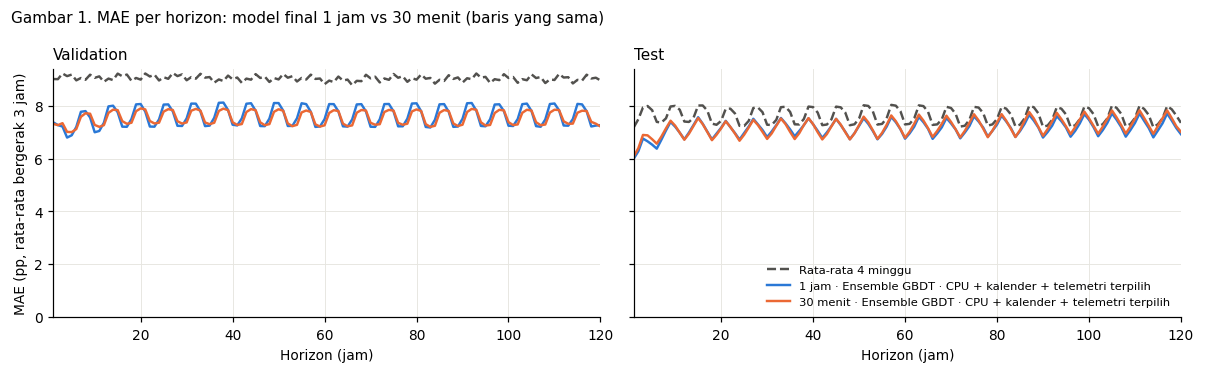

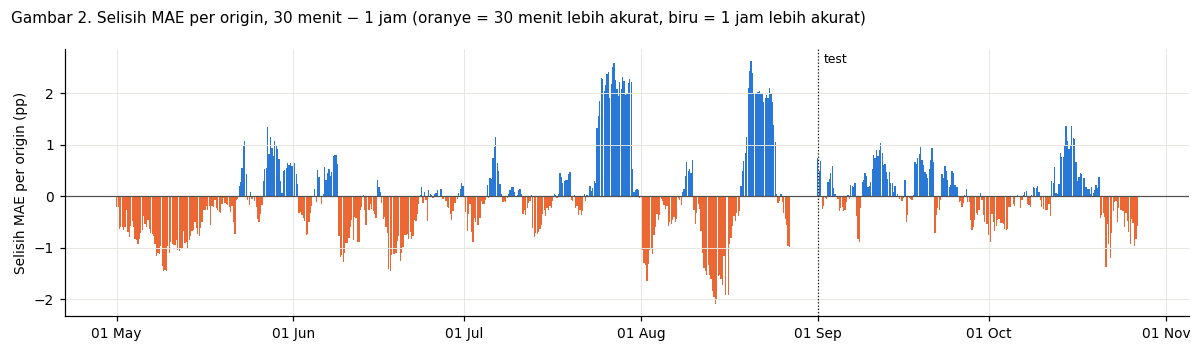

In [16]:
# Gambar 1: MAE per horizon, model final kedua varian dan pembanding
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (ph, g) in zip(axs, A.groupby("phase", sort=False)):
    for c, col, ls, lab in ((f"{BASE['mean4w']}|60", RCOL["base"], "--", BASE["mean4w"]), (F60, RCOL["60"], "-", f"1 jam · {FINAL60}"), (F30, RCOL["30"], "-", f"30 menit · {NAME[FINAL]}")):
        s = (g[c] - g.y).abs().groupby(g.h).mean().rolling(3, center=True, min_periods=1).mean()
        ax.plot(s.index, s.values, color=col, ls=ls, lw=1.6, label=lab)
    ax.set_title(FASE[ph]); ax.set_xlabel("Horizon (jam)"); ax.set_xlim(1, H_JAM)
axs[0].set_ylabel("MAE (pp, rata-rata bergerak 3 jam)"); axs[0].set_ylim(0, None); axs[1].legend(frameon=False, fontsize=7.5, loc="lower right")
fig.suptitle("Gambar 1. MAE per horizon: model final 1 jam vs 30 menit (baris yang sama)", x=.01, ha="left", fontsize=10); fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figures/01_mae_per_horizon.png", bbox_inches="tight"); plt.show()

# Gambar 2: selisih MAE per origin (30 − 60) sepanjang waktu
fig, ax = plt.subplots(figsize=(11, 3.2))
d = ((A[F30] - A.y).abs() - (A[F60] - A.y).abs()).groupby(A.origin).mean()
ax.axhline(0, color=INK2, lw=.8); ax.bar(d.index, d.values, width=.22, color=np.where(d.values < 0, RCOL["30"], RCOL["60"]))
ax.axvline(pd.Timestamp("2026-09-01"), color=INK, lw=.8, ls=":"); ax.text(pd.Timestamp("2026-09-02"), ax.get_ylim()[1] * .9, "test", fontsize=8)
ax.set_ylabel("Selisih MAE per origin (pp)"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.suptitle("Gambar 2. Selisih MAE per origin, 30 menit − 1 jam (oranye = 30 menit lebih akurat, biru = 1 jam lebih akurat)", x=.01, ha="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/02_selisih_per_origin.png", bbox_inches="tight"); plt.show()

## 9. Uji sensitivitas: label dari data 30 menit

Tabel 2 menunjukkan bahwa rata-rata dua baris 30 menit tidak persis sama dengan CPU di data 1 jam. Model 30 menit dilatih dengan label dari data 30 menit, sedangkan penilaian utama memakai label data 1 jam, sehingga model 30 menit bisa sedikit dirugikan.
Di sini kedua model dinilai ulang dengan label alternatif: **rata-rata dua baris 30 menit** di jam target. Hanya jam dengan kedua label 30 menit teramati yang dipakai.

In [17]:
AS = A[A.y30.notna()]
rows = [{"Fase": FASE[ph], "Label": "rata-rata 2 × 30 menit", "MAE 1 jam": (g[F60] - g.y30).abs().mean(), "MAE 30 menit": (g[F30] - g.y30).abs().mean()} for ph, g in AS.groupby("phase", sort=False)]
rows += [{"Fase": FASE[ph], "Label": "data 1 jam (utama)", "MAE 1 jam": (g[F60] - g.y).abs().mean(), "MAE 30 menit": (g[F30] - g.y).abs().mean()} for ph, g in AS.groupby("phase", sort=False)]
show(pd.DataFrame(rows).assign(**{"Selisih (30 − 60)": lambda x: x["MAE 30 menit"] - x["MAE 1 jam"]}).sort_values(["Fase", "Label"]),
     {"MAE 1 jam": "{:.3f}", "MAE 30 menit": "{:.3f}", "Selisih (30 − 60)": "{:+.3f}"}, "Tabel 16. Model final dengan dua label")
DMS = dm_rows(AS, PAIRS[:1], ycol="y30"); show_dm(DMS, "Tabel 17. Uji Diebold–Mariano model final dengan label rata-rata 2 × 30 menit (negatif = 30 menit lebih akurat)")

Fase,Label,MAE 1 jam,MAE 30 menit,Selisih (30 − 60)
Test,data 1 jam (utama),7.138,7.184,+0.045
Test,rata-rata 2 × 30 menit,7.137,7.182,+0.046
Validation,data 1 jam (utama),7.570,7.497,-0.073
Validation,rata-rata 2 × 30 menit,7.587,7.511,-0.076


Fase,Model A,Dibanding (B),Selisih MAE (A − B),CI 95% bawah,CI 95% atas,p,T origin,m,Kesimpulan
Validation,30 menit · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),1 jam · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),-0.078,-0.434,+0.278,0.647,471,7,tidak berbeda nyata
Test,30 menit · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),1 jam · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),+0.045,-0.189,+0.279,0.681,225,6,tidak berbeda nyata


## 10. Akurasi pada resolusi 30 menit

Bagian ini menjawab pertanyaan yang berbeda: bila yang dibutuhkan adalah prakiraan **per 30 menit**, seberapa akurat model 30 menit?
Pembandingnya adalah prakiraan model final 1 jam yang dipakai untuk kedua setengah jam di dalam jam itu, karena model 1 jam memang tidak bisa memberi nilai yang lebih rinci. Label = CPU 30 menit mentah.
MAE di sini **tidak** bisa dibandingkan dengan MAE per jam di bagian 8, karena deret 30 menit lebih berfluktuasi.

In [18]:
B = N30[N30.y.notna()][["origin", "target_time", "target_jam", "h", "y", "phase", FINAL, "mean4w"]].merge(
    P60[["origin", "target_time", FINAL60]].rename(columns={"target_time": "target_jam", FINAL60: "f60"}), on=["origin", "target_jam"], how="inner")
B = B[B.origin.isin(A.origin.unique())].sort_values(["origin", "target_time"]).reset_index(drop=True)
rows = []
for ph, g in B.groupby("phase", sort=False):
    for c, lab in ((FINAL, f"30 menit · {NAME[FINAL]}"), ("f60", f"1 jam · {FINAL60} (nilai jam dipakai untuk kedua setengah jam)"), ("mean4w", f"30 menit · {BASE['mean4w']}")):
        e = g[c] - g.y; rows.append({"Fase": FASE[ph], "Prakiraan": lab, "MAE (30 menit)": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "Bias": e.mean(), "MAE puncak": e[g.y >= HIGH].abs().mean()})
show(pd.DataFrame(rows), {"MAE (30 menit)": "{:.3f}", "RMSE": "{:.2f}", "Bias": "{:+.2f}", "MAE puncak": "{:.2f}"}, "Tabel 18. Akurasi pada resolusi 30 menit")
DMN = dm_rows(B, [(FINAL, "f60", f"30 menit · {NAME[FINAL]}", f"1 jam · {FINAL60}")]); show_dm(DMN, "Tabel 19. Uji Diebold–Mariano pada resolusi 30 menit (negatif = model 30 menit lebih akurat)")

Fase,Prakiraan,MAE (30 menit),RMSE,Bias,MAE puncak
Validation,30 menit · Ensemble GBDT · CPU + kalender + telemetri terpilih,8.054,10.68,+1.25,11.38
Validation,1 jam · Ensemble GBDT · CPU + kalender + telemetri terpilih (nilai jam dipakai untuk kedua setengah jam),8.374,10.93,+1.38,11.54
Validation,30 menit · Rata-rata 4 minggu,9.504,13.40,+0.90,15.65
Test,30 menit · Ensemble GBDT · CPU + kalender + telemetri terpilih,7.647,10.18,-1.26,21.55
Test,1 jam · Ensemble GBDT · CPU + kalender + telemetri terpilih (nilai jam dipakai untuk kedua setengah jam),8.073,10.51,-0.93,21.28
Test,30 menit · Rata-rata 4 minggu,8.139,10.83,-0.58,27.87


Fase,Model A,Dibanding (B),Selisih MAE (A − B),CI 95% bawah,CI 95% atas,p,T origin,m,Kesimpulan
Validation,30 menit · Ensemble GBDT · CPU + kalender + telemetri terpilih,1 jam · Ensemble GBDT · CPU + kalender + telemetri terpilih,-0.321,-0.658,+0.016,0.060,471,7,tidak berbeda nyata
Test,30 menit · Ensemble GBDT · CPU + kalender + telemetri terpilih,1 jam · Ensemble GBDT · CPU + kalender + telemetri terpilih,-0.427,-0.684,-0.170,0.004,225,6,lebih baik


## 11. Analisis tambahan: riwayat 30 menit yang lebih panjang

Data 30 menit dimulai 1 Agu 2024, sekitar 14,5 bulan lebih awal dari data 1 jam. Di sini model 30 menit dilatih ulang dengan **seluruh** riwayat itu.
Konfigurasi model **tidak dipilih ulang**: dipakai konfigurasi beku dari bagian 6, supaya yang berubah hanya panjang riwayat. Fitur ekspansif (profil setengah-jam-minggu) juga ikut memakai riwayat yang lebih panjang.
Catatan: Tabel 3 menunjukkan riwayat 2024 punya celah besar (Okt–Nov 2024). Aturan C1–C3 tetap berlaku, sehingga celah panjang tidak diimputasi.

riwayat panjang: 2,062,827 baris training 30 menit (disiapkan 5 detik)


  panjang validation 2026-05-01 HistGradientBoosting · CPU + kalender · target residual · bobot rata: 38 s


  panjang validation 2026-05-01 HistGradientBoosting · CPU + kalender + telemetri terpilih · target residual · bobot rata: 55 s


  panjang validation 2026-05-01 LightGBM · CPU + kalender · target residual · bobot half-life 180 hari: 50 s


  panjang validation 2026-05-01 LightGBM · CPU + kalender + telemetri terpilih · target residual · bobot half-life 180 hari: 53 s


  panjang validation 2026-05-01 Ridge · CPU + kalender · target residual · alpha 1000: 264 s


... (43 outputs left out)

  panjang test 2026-10-01 XGBoost · CPU + kalender + telemetri terpilih · target residual · bobot rata: 78 s


test: dilatih 26.4 menit


Fase,Varian · model final,Origin,MAE,MAE relatif,RMSE,Bias,MAE puncak,Bias puncak
Validation,1 jam · Ensemble GBDT · CPU + kalender + telemetri terpilih,471,7.605,0.842,9.93,+1.34,9.66,-8.99
Validation,30 menit · Ensemble GBDT · CPU + kalender + telemetri terpilih,471,7.535,0.834,9.94,+1.21,9.81,-8.71
Validation,"30 menit, riwayat panjang · Ensemble GBDT · CPU + kalender + telemetri terpilih",471,7.535,0.834,9.94,+0.25,11.97,-11.05
Test,1 jam · Ensemble GBDT · CPU + kalender + telemetri terpilih,225,7.138,0.937,9.25,-0.93,15.97,-15.95
Test,30 menit · Ensemble GBDT · CPU + kalender + telemetri terpilih,225,7.184,0.943,9.31,-1.26,16.53,-16.53
Test,"30 menit, riwayat panjang · Ensemble GBDT · CPU + kalender + telemetri terpilih",225,6.983,0.917,9.10,-0.39,16.46,-16.44


Fase,Model A,Dibanding (B),Selisih MAE (A − B),CI 95% bawah,CI 95% atas,p,T origin,m,Kesimpulan
Validation,"30 menit, riwayat panjang · final",30 menit · final,+0.001,-0.339,+0.341,0.995,471,7,tidak berbeda nyata
Validation,"30 menit, riwayat panjang · final",1 jam · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),-0.070,-0.352,+0.212,0.603,471,7,tidak berbeda nyata
Test,"30 menit, riwayat panjang · final",30 menit · final,-0.200,-0.518,+0.117,0.195,225,6,tidak berbeda nyata
Test,"30 menit, riwayat panjang · final",1 jam · final (Ensemble GBDT · CPU + kalender + telemetri terpilih),-0.155,-0.497,+0.186,0.342,225,6,tidak berbeda nyata


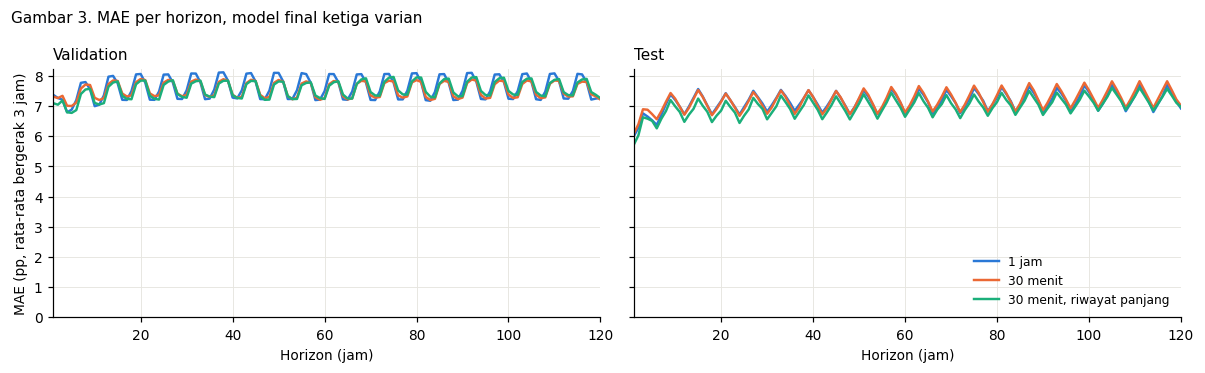

In [19]:
if RUN_RIWAYAT_PANJANG:
    CTX.pop("TR", None)                                   # hemat memori: baris training varian utama tidak dipakai lagi
    t0 = time.time(); CTXL = siapkan(DF_ALL, "panjang")
    assert [c for c in CTXL["TR"].columns if c not in META] == FEATS_ALL
    print(f"riwayat panjang: {len(CTXL['TR']):,} baris training 30 menit (disiapkan {time.time() - t0:.0f} detik)")
    PL = []
    for ph in SPLIT:
        SPECS_L = with_twins(CTXL, BEST.values(), [ph])
        (p_, log_), how_ = run_phase(CTXL, ph, SPECS_L); print(f"{ph}: {how_}"); PL.append(add_ens(apply_fallback(CTXL, p_, SPECS_L)))
    del CTXL
    JL = ke_jam(pd.concat(PL, ignore_index=True), SHOWN)
    JL[["origin", "target_time", "h", "y", "y30", "phase", "refit", "fallback"] + SHOWN].rename(columns=NAME).to_csv(f"{OUT_DIR}/prediksi_30m_riwayat_panjang_per_jam.csv.gz", index=False, float_format="%.4f")
    AL = A.merge(JL[["origin", "target_time"] + SHOWN].rename(columns={c: f"{NAME[c]}|30P" for c in SHOWN}), on=["origin", "target_time"], how="inner").sort_values(["origin", "h"]).reset_index(drop=True)
    FL = f"{NAME[FINAL]}|30P"
    rows = []
    for ph, g in AL.groupby("phase", sort=False):
        for c, lab in ((F60, f"1 jam · {FINAL60}"), (F30, f"30 menit · {NAME[FINAL]}"), (FL, f"30 menit, riwayat panjang · {NAME[FINAL]}")):
            rows.append({"Fase": FASE[ph], "Varian · model final": lab, "Origin": g.origin.nunique(), **met(g, c)})
    show(pd.DataFrame(rows), {"Origin": "{:d}"} | FMT, "Tabel 20. Pengaruh panjang riwayat (baris yang sama di ketiga varian)")
    DML = dm_rows(AL, [(FL, F30, "30 menit, riwayat panjang · final", "30 menit · final"), (FL, F60, "30 menit, riwayat panjang · final", f"1 jam · final ({FINAL60})")])
    DML.to_csv(f"{OUT_DIR}/uji_dm_riwayat_panjang.csv", index=False)
    show_dm(DML, "Tabel 21. Uji Diebold–Mariano riwayat panjang (negatif = model A lebih akurat)")
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
    for ax, (ph, g) in zip(axs, AL.groupby("phase", sort=False)):
        for c, k in ((F60, "60"), (F30, "30"), (FL, "30P")):
            s = (g[c] - g.y).abs().groupby(g.h).mean().rolling(3, center=True, min_periods=1).mean(); ax.plot(s.index, s.values, color=RCOL[k], lw=1.6, label=RES[k])
        ax.set_title(FASE[ph]); ax.set_xlabel("Horizon (jam)"); ax.set_xlim(1, H_JAM)
    axs[0].set_ylabel("MAE (pp, rata-rata bergerak 3 jam)"); axs[0].set_ylim(0, None); axs[1].legend(frameon=False, fontsize=8, loc="lower right")
    fig.suptitle("Gambar 3. MAE per horizon, model final ketiga varian", x=.01, ha="left", fontsize=10); fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/figures/03_mae_riwayat_panjang.png", bbox_inches="tight"); plt.show()
else:
    DML = None; display(Markdown("Dilewati (`RUN_RIWAYAT_PANJANG = False`)."))

## 12. Kesimpulan

In [20]:
def kal(r): return f"{r['Selisih MAE (A − B)']:+.3f} pp [CI 95% {r['CI 95% bawah']:+.3f}; {r['CI 95% atas']:+.3f}], p = {r['p']:.3f} → **{r['Kesimpulan']}**"
utama = {r.Fase: r for _, r in DM[DM["Model A"].str.startswith("30 menit · final") & DM["Dibanding (B)"].str.startswith("1 jam · final")].iterrows()}
ts = utama["Test"]; vs = utama["Validation"]
jawab = {"lebih baik": "**lebih akurat**", "lebih buruk": "**kurang akurat**", "tidak berbeda nyata": "**tidak terbukti berbeda**"}[ts["Kesimpulan"]]
fam = DM[(DM.Fase == "Test") & ~DM["Model A"].str.contains("final")]
lines = [f"**Jawaban (aturan keputusan, periode test, eksploratori):** prakiraan CPU per jam dari model yang dilatih dengan data 30 menit {jawab} dibanding model 1 jam.",
         "", f"- Model final 30 menit: {NAME[FINAL]}. Model final 1 jam: {FINAL60}.",
         f"- Test, selisih MAE (30 menit − 1 jam): {kal(ts)}.", f"- Validation, selisih MAE (30 menit − 1 jam): {kal(vs)}.",
         f"- Per keluarga model di test: {int((fam.Kesimpulan == 'lebih baik').sum())} lebih baik, {int((fam.Kesimpulan == 'lebih buruk').sum())} lebih buruk, "
         f"{int((fam.Kesimpulan == 'tidak berbeda nyata').sum())} tidak berbeda nyata (dari {len(fam)} pasangan, Tabel 14).",
         f"- Sensitivitas label rata-rata 2 × 30 menit, test: {kal(DMS[DMS.Fase == 'Test'].iloc[0])}.",
         f"- Pada resolusi 30 menit (Tabel 19), test: {kal(DMN[DMN.Fase == 'Test'].iloc[0])}."]
if DML is not None:
    r = DML[(DML.Fase == "Test") & DML["Dibanding (B)"].str.startswith("30 menit")].iloc[0]; lines.append(f"- Riwayat panjang vs riwayat sama (30 menit), test: {kal(r)}.")
    r = DML[(DML.Fase == "Test") & DML["Dibanding (B)"].str.startswith("1 jam")].iloc[0]; lines.append(f"- Riwayat panjang (30 menit) vs 1 jam, test: {kal(r)}.")
lines += ["", "**Batasan.** Periode test sudah pernah dilihat saat membangun model 1 jam, dan sebagian kandidat model dibatasi pada grid yang sama. "
          f"Klaim akhir sebaiknya menunggu uji pada data setelah 1 November 2026 dengan seleksi yang sudah dibekukan di `{SEL_PATH}`."]
display(Markdown("\n".join(lines)))
json.dump({"model_final_30m": NAME[FINAL], "model_final_1jam": FINAL60, "dm_utama": {k: {kk: (vv if isinstance(vv, str) else float(vv)) for kk, vv in v.items() if kk not in ("Fase",)} for k, v in utama.items()},
           "seleksi_sha256": open(SEL_PATH + ".sha256").read()}, open(f"{OUT_DIR}/ringkasan_30m_vs_1jam.json", "w"), indent=2, default=str)

**Jawaban (aturan keputusan, periode test, eksploratori):** prakiraan CPU per jam dari model yang dilatih dengan data 30 menit **tidak terbukti berbeda** dibanding model 1 jam.

- Model final 30 menit: Ensemble GBDT · CPU + kalender + telemetri terpilih. Model final 1 jam: Ensemble GBDT · CPU + kalender + telemetri terpilih.
- Test, selisih MAE (30 menit − 1 jam): +0.045 pp [CI 95% -0.188; +0.278], p = 0.682 → **tidak berbeda nyata**.
- Validation, selisih MAE (30 menit − 1 jam): -0.071 pp [CI 95% -0.432; +0.289], p = 0.679 → **tidak berbeda nyata**.
- Per keluarga model di test: 0 lebih baik, 0 lebih buruk, 10 tidak berbeda nyata (dari 10 pasangan, Tabel 14).
- Sensitivitas label rata-rata 2 × 30 menit, test: +0.045 pp [CI 95% -0.189; +0.279], p = 0.681 → **tidak berbeda nyata**.
- Pada resolusi 30 menit (Tabel 19), test: -0.427 pp [CI 95% -0.684; -0.170], p = 0.004 → **lebih baik**.
- Riwayat panjang vs riwayat sama (30 menit), test: -0.200 pp [CI 95% -0.518; +0.117], p = 0.195 → **tidak berbeda nyata**.
- Riwayat panjang (30 menit) vs 1 jam, test: -0.155 pp [CI 95% -0.497; +0.186], p = 0.342 → **tidak berbeda nyata**.

**Batasan.** Periode test sudah pernah dilihat saat membangun model 1 jam, dan sebagian kandidat model dibatasi pada grid yang sama. Klaim akhir sebaiknya menunggu uji pada data setelah 1 November 2026 dengan seleksi yang sudah dibekukan di `outputs_30m/seleksi_beku_30m.json`.

## Daftar pustaka

- Coroneo, L., & Iacone, F. (2020). Comparing predictive accuracy in small samples using fixed-smoothing asymptotics. *Journal of Applied Econometrics, 35*(4), 391–409.
- Hewamalage, H., Ackermann, K., & Bergmeir, C. (2023). Forecast evaluation for data scientists: Common pitfalls and best practices. *Data Mining and Knowledge Discovery, 37*, 788–832.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts.

Pustaka lain untuk metode yang sama (fitur, model, kalender, pembersihan) ada di `skripsi_forecast_v3.ipynb`.